# Cuaderno de la aplicación

Este cuaderno contiene el código de la aplicación Streamlit. Cada archivo (`home.py`, `pages/`, `common/`,
`controllers/` y `models/`) está en una celda, precedido de una breve explicación. La lógica se escribe y se prueba aquí
y después se exporta a los archivos `.py`.

## Exportación

- La primera línea de cada celda exportable es una marca: `#| archivo: controllers/metrics.py`. Es un comentario, por
  lo que la celda se puede ejecutar con normalidad.
- Las celdas Raw también se exportan. Se usan para el código que no es Python (SQL, CSS, TOML) y para las páginas de
  Streamlit, que solo se ejecutan con `streamlit run`.
- La última sección exporta los archivos y comprueba que coinciden con los de la aplicación. Por defecto escribe en una
  carpeta temporal; solo `exportar(APP)` sobrescribe la aplicación.

El exportador lee el cuaderno guardado en disco, por lo que hay que guardarlo antes de exportar.

## Ejecución

Desde la carpeta de la aplicación y con Jupyter instalado (no figura en `requirements.txt`):

```bash
jupyter notebook docs/cuaderno_app.ipynb
```

In [1]:
# Preparación: localizar la carpeta de la aplicación (la que contiene home.py) y poder importar sus módulos.
import os
import sqlite3
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image as ImagenPNG, display  # con alias: `escudos_model.py` importa otra `Image` (la de PIL)

APP = Path.cwd().resolve()
if APP.name == "docs":
    APP = APP.parent
assert (APP / "home.py").exists(), "Ejecuta el cuaderno desde la carpeta de la aplicación o desde docs/"
sys.path.insert(0, str(APP))  # así `import controllers...` y `import models...` funcionan igual que en la app

# Los módulos usan Path(__file__) para sus rutas. En un cuaderno no existe: se fija como si estuviera en models/.
__file__ = str(APP / "models" / "cuaderno.py")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CUADERNO = APP / "docs" / "cuaderno_app.ipynb"

# Silencia los avisos de caché de Streamlit fuera de un servidor.
from streamlit.logger import set_log_level

set_log_level("ERROR")
print("Aplicación en:", APP.name)

Aplicación en: app


### Exportador

`celdas_exportables` lee el cuaderno guardado (un `.ipynb` es un JSON) y devuelve `{ruta: contenido}` de las celdas
marcadas. `exportar` las escribe en una carpeta y rechaza cualquier ruta que salga de ella. Aquí solo se definen; se
ejecutan en la última sección.

In [2]:
import json

MARCA = "#| archivo:"


def celdas_exportables(cuaderno: Path = CUADERNO) -> dict[str, str]:
    '''Lee el cuaderno guardado y devuelve {ruta del archivo: contenido} de las celdas marcadas.'''
    celdas = json.loads(cuaderno.read_text(encoding="utf-8"))["cells"]
    archivos: dict[str, str] = {}
    for celda in celdas:
        if celda["cell_type"] not in ("code", "raw"):
            continue
        primera, _, resto = "".join(celda["source"]).partition("\n")
        if primera.startswith(MARCA):
            ruta = primera[len(MARCA):].strip()
            if ruta in archivos:
                raise ValueError(f"Archivo repetido en el cuaderno: {ruta}")
            archivos[ruta] = resto + "\n"
    return archivos


def exportar(destino: Path, cuaderno: Path = CUADERNO) -> dict[str, str]:
    '''Escribe en `destino` los archivos marcados del cuaderno y devuelve {ruta: contenido}.'''
    archivos = celdas_exportables(cuaderno)
    raiz = destino.resolve()
    for ruta, contenido in archivos.items():
        objetivo = (raiz / ruta).resolve()
        if raiz not in objetivo.parents:
            raise ValueError(f"La ruta {ruta!r} sale de la carpeta de destino")
        objetivo.parent.mkdir(parents=True, exist_ok=True)
        objetivo.write_text(contenido, encoding="utf-8")
    return archivos

### Capas

| Capa | Carpeta | Función |
|---|---|---|
| Datos de origen | `scripts/`, `data/raw/` | Descargar los datos y construir la base |
| Modelos | `models/` | Leer una fuente y devolver un `DataFrame` |
| Controladores | `controllers/` | Calcular métricas, tablas, gráficas e informes |
| Comunes | `common/` | Login, menú, tema, impresión y PDF |
| Páginas | `home.py`, `pages/` | Mostrar filtros, tablas, gráficas y botones |

Cuanto más abajo está la lógica, más fácil es probarla. Los controladores reciben un `DataFrame` y devuelven otro, y se
prueban con `pytest` sin navegador. Las páginas solo llaman a esas funciones.

Recorrido de un dato:

```text
web pública ──fetch_*.py──▶ data/raw/*.json ──build_db.py──▶ viajes_fatiga.db ──precompute_metrics.py──▶ metricas.parquet
                                                                   │                                         │
                                                       models/ (leer SQLite)                  models/ (leer el parquet)
                                                                   └──────────────┬──────────────────────────┘
                                                                         controllers/ (calcular y preparar)
                                                                                  │
                                                                      pages/ (filtros, tablas, gráficas, PDF)
```

## 1. Datos de origen

Los scripts de `scripts/` se ejecutan a mano para actualizar los datos y no forman parte de la aplicación publicada.
Este cuaderno no los genera.

1. `fetch_euroleague.py` descarga Euroliga y EuroCup a `data/raw/api/`.
2. `fetch_acb.py` descarga la ACB a `data/raw/acb/`.
3. `build_db.py` construye `data/viajes_fatiga.db` a partir de `data/raw/`.
4. `precompute_metrics.py` guarda las métricas en `data/metricas.parquet`.

`build_db.py` no necesita internet: con los JSON de `data/raw/` se reconstruye siempre la misma base. Los scripts de
descarga usan un `User-Agent` propio y esperan un segundo entre peticiones.

In [3]:
import ast

for script in ["fetch_euroleague.py", "fetch_acb.py", "build_db.py", "precompute_metrics.py"]:
    doc = ast.get_docstring(ast.parse((APP / "scripts" / script).read_text(encoding="utf-8")))
    print(f"--- scripts/{script}")
    print("\n".join(doc.splitlines()[:4]), end="\n\n")

print("Archivos de data/raw/ que usa build_db.py:")
for ruta in sorted((APP / "data" / "raw").rglob("*")):
    if ruta.is_file():
        print(f"  {ruta.relative_to(APP / 'data' / 'raw')!s:<34} {ruta.stat().st_size / 1024:>8.0f} KB")

--- scripts/fetch_euroleague.py
Descarga de Euroliga (E) y EuroCup (U) desde la API pública v2 a data/raw/api/.

Por cada competición y temporada guarda:
  <comp><año>.json          calendario y resultados (se vuelve a pedir con --force)

--- scripts/fetch_acb.py
Descarga de la ACB: calendario y resultados (acb.com) y minutos por jugador (live.acb.com).

Solo existe la temporada en curso: la página del calendario no admite otra. Guarda en data/raw/acb/:
  calendario_<año>.json   partidos, resultados y estado (se descarga entero cada vez, es una sola petición)

--- scripts/build_db.py
Construye app/data/viajes_fatiga.db con lo descargado por fetch_euroleague.py y fetch_acb.py más las sedes (CSV).

Uso: python scripts/build_db.py [--from 2022] [--to 2026]
Lee solo data/raw/: no necesita ninguna ruta externa. La base se recrea desde cero en cada ejecución.

--- scripts/precompute_metrics.py
Precalcula las métricas y las guarda en app/data/metricas.parquet para que la app no las calcule al

### `controllers/ingest.py`

Lógica de la ingesta, sin dependencias externas. Normaliza los partidos de la API (`parse_api_game`), identifica
pabellones y clubes duplicados (`group_venues`, `club_canonical`) y calcula distancias (`haversine_km`).

In [4]:
#| archivo: controllers/ingest.py
"""Lógica pura de ingesta: normaliza partidos de la API de Euroliga/EuroCup y resuelve clubes y sedes."""
import math
import unicodedata
from dataclasses import dataclass

VENUE_ACRONYMS = {"BJK", "PAOK", "USH", "CSKA", "LDLC", "SAP", "BLM", "PG"}
VENUE_LOWER = {"de", "del", "della", "dello", "da", "do", "dos", "di", "la", "le", "and"}
VENUE_FIXES = {"PALAEUR": "PalaEur", "PALADOZZA": "PalaDozza", "PALALEONESSA A2A": "PalaLeonessa A2A"}
CLUB_FIXES = {"NINERS Chemnitz": "Niners Chemnitz", "BOSNA BH Telecom Sarajevo": "Bosna BH Telecom Sarajevo"}


def normalize_venue_name(name: str) -> str:
    """Nombre de pabellón con mayúscula inicial en cada palabra; solo toca los nombres escritos todo en mayúsculas.

    Se respetan las siglas (BJK, PAOK, SAP...), las partículas en minúscula (de, dello) y los tokens con cifras (A2A).
    """
    name = " ".join(name.replace("&", " & ").split())
    if name != name.upper():
        return name  # ya viene en mayúsculas y minúsculas
    if name in VENUE_FIXES:
        return VENUE_FIXES[name]
    words = []
    for i, word in enumerate(name.split()):
        if word in VENUE_ACRONYMS or any(c.isdigit() for c in word) or word == "&":
            words.append(word)
        elif word.lower() in VENUE_LOWER and i > 0:
            words.append(word.lower())
        else:
            words.append("-".join(part.capitalize() for part in word.split("-")))
    return " ".join(words)


def tidy_club_name(name: str) -> str:
    """Nombre de club con cada palabra empezando en mayúscula y sin marcas escritas todo en mayúsculas (NINERS, BOSNA)."""
    name = CLUB_FIXES.get(name, name)
    return " ".join(word[:1].upper() + word[1:] for word in name.split())


def norm(text: str) -> str:
    """Minúsculas, sin tildes ni espacios sobrantes, para comparar nombres."""
    nfkd = unicodedata.normalize("NFKD", text or "")
    return " ".join("".join(c for c in nfkd if not unicodedata.combining(c)).lower().split())


def haversine_km(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Distancia en km sobre la esfera terrestre entre dos coordenadas."""
    r = 6371.0088
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi = p2 - p1
    dlmb = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlmb / 2) ** 2
    return 2 * r * math.asin(math.sqrt(a))


@dataclass(frozen=True)
class Venue:
    """Sede candidata para unir duplicados."""

    key: str
    nombre: str
    lat: float
    lon: float
    precision: str


def same_venue(a: Venue, b: Venue, max_km: float = 0.25) -> bool:
    """Misma sede si comparten nombre o están a menos de `max_km` y ambas tienen coordenada precisa."""
    if norm(a.nombre) == norm(b.nombre):
        return True
    if "ciudad" in (a.precision, b.precision):
        return False
    return haversine_km(a.lat, a.lon, b.lat, b.lon) <= max_km


def group_venues(venues: list[Venue]) -> dict[str, int]:
    """Asigna un número de grupo a cada clave de sede; las sedes iguales comparten grupo."""
    parent = list(range(len(venues)))

    def find(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, a in enumerate(venues):
        for j in range(i + 1, len(venues)):
            if same_venue(a, venues[j]):
                parent[find(j)] = find(i)
    roots: dict[int, int] = {}
    return {v.key: roots.setdefault(find(i), len(roots)) for i, v in enumerate(venues)}


def club_canonical(
    comp: str, code: str, names_by_season: dict[int, str], crosswalk: dict[tuple[str, str], str]
) -> str:
    """Nombre canónico: el del crosswalk si existe; si no, el nombre más reciente de ese código."""
    if (comp, code) in crosswalk:
        return crosswalk[(comp, code)]
    return names_by_season[max(names_by_season)]


def parse_api_game(game: dict, comp: str) -> dict | None:
    """Convierte un partido de la API v2 en una fila plana; devuelve None si algún club es virtual."""
    local, road = game["local"], game["road"]
    if local["club"].get("isVirtual") or road["club"].get("isVirtual"):
        return None
    played = bool(game.get("played"))
    venue = game.get("venue") or {}
    return {
        "game_code": game["gameCode"],
        "season": game["season"]["year"],
        "comp": comp,
        "fecha": (game.get("localDate") or game["date"])[:10],
        "hora_utc": (game.get("utcDate") or "").rstrip("Z") or None,
        "jornada": game.get("round"),
        "fase": (game.get("phaseType") or {}).get("name"),
        "local_code": local["club"]["code"],
        "local_name": local["club"]["name"],
        "road_code": road["club"]["code"],
        "road_name": road["club"]["name"],
        "venue_code": venue.get("code"),
        "neutral": int(bool(game.get("isNeutralVenue"))),
        "jugado": int(played),
        "pts_local": local.get("score") if played else None,
        "pts_visitante": road.get("score") if played else None,
    }


def alias_ranges(
    rows: list[tuple[str, str, str, int]], last_season: int
) -> list[tuple[str, str, str, int, int | None]]:
    """Agrupa (comp, código, nombre, temporada) en rangos; hasta=None si llega a la última temporada."""
    spans: dict[tuple[str, str, str], list[int]] = {}
    for comp, code, name, season in rows:
        spans.setdefault((comp, code, name), []).append(season)
    return [
        (comp, code, name, min(s), None if max(s) == last_season else max(s))
        for (comp, code, name), s in sorted(spans.items())
    ]

### `controllers/acb_parse.py`

La ACB no ofrece API. El calendario está en los datos incrustados de la página y los minutos, en tablas HTML. Cada
partido se valida: los puntos de la fila «Totales» deben coincidir con el marcador, y si no coinciden se lanza un error
en lugar de guardar datos mal leídos.

In [5]:
#| archivo: controllers/acb_parse.py
"""Lectura de las páginas públicas de la ACB: calendario (acb.com) y estadísticas de partido (live.acb.com).

Lógica pura sobre el HTML descargado; la descarga está en `scripts/fetch_acb.py`. `bs4` solo se importa al leer
estadísticas, porque la app publicada no lo necesita.
"""
import json
import re

PLAYED_STATUS = "FINALIZED"
_CHUNK = re.compile(r'self\.__next_f\.push\(\[1,"(.*?)"\]\)</script>', re.DOTALL)
_TEAM_REF = re.compile(r":teams:(\d+)$")


def _next_payload(html: str) -> str:
    """Une los fragmentos `self.__next_f.push` de Next.js en un solo texto."""
    chunks = _CHUNK.findall(html)
    if not chunks:
        raise ValueError("La página no trae datos de Next.js: ha cambiado el formato.")
    return "".join(json.loads(f'"{c}"') for c in chunks)


def parse_calendar(html: str) -> dict:
    """Calendario de la temporada en curso: equipos y partidos con resultado y estado.

    Cada partido lleva `home` y `away` como código ACB de tres letras (p. ej. «BAR», «K&U»).
    """
    payload = _next_payload(html)
    start = payload.find('"rounds":[')
    team_start = payload.rfind('"teams":[', 0, start)
    if start < 0 or team_start < 0:
        raise ValueError("No se encuentran las jornadas ni los equipos en la página.")
    decoder = json.JSONDecoder()
    rounds, _ = decoder.raw_decode(payload[start + len('"rounds":'):])
    teams, _ = decoder.raw_decode(payload[team_start + len('"teams":'):])
    matches = []
    for rnd in rounds:
        for m in rnd["matches"]:
            home = teams[int(_TEAM_REF.search(m["homeTeam"]).group(1))]
            away = teams[int(_TEAM_REF.search(m["awayTeam"]).group(1))]
            played = m["matchStatus"] == PLAYED_STATUS
            matches.append({
                "id": m["id"],
                "jornada": rnd["roundNumber"],
                "fecha_utc": m["startDateTime"].rstrip("Z"),
                "estado": m["matchStatus"],
                "jugado": played,
                "home": home["abbreviatedName"],
                "home_name": home["fullName"],
                "away": away["abbreviatedName"],
                "away_name": away["fullName"],
                "pts_local": m["homeTeamScore"] if played else None,
                "pts_visitante": m["awayTeamScore"] if played else None,
            })
    seasons = {m["seasonStartYear"] for rnd in rounds for m in rnd["matches"]}
    if len(seasons) != 1:
        raise ValueError(f"Se esperaba una sola temporada y hay {sorted(seasons)}.")
    return {"temporada": seasons.pop(), "partidos": matches}


def minutes_to_float(text: str) -> float:
    """«21:02» -> 21,03 minutos; vacío o ilegible -> 0."""
    match = re.fullmatch(r"\s*(\d+):(\d{2})\s*", text or "")
    return int(match.group(1)) + int(match.group(2)) / 60 if match else 0.0


def _team_rows(table) -> tuple[list[dict], int]:
    """Jugadores con minutos de una tabla de estadísticas y los puntos que suma la fila «Totales»."""
    rows, total = [], 0
    for tr in table.find_all("tr")[1:]:
        cells = tr.find_all("td")
        if len(cells) < 3:
            continue
        if cells[0].get_text(" ", strip=True) == "Totales":
            total = int(cells[2].get_text(strip=True) or 0)
            continue
        name_tag = cells[0].select_one('[class*="playerName"]')
        if name_tag is None:
            continue
        dorsal = name_tag.find("span")
        if dorsal is not None:
            dorsal.extract()  # el dorsal va dentro del mismo texto que el nombre
        minutes = minutes_to_float(cells[1].get_text(strip=True))
        if minutes <= 0:
            continue  # no jugó
        rows.append({
            "jugador": name_tag.get_text(" ", strip=True),
            "titular": int(cells[0].select_one('[class*="playerStarterIcon"]') is not None),
            "minutos": round(minutes, 2),
            "puntos": int(cells[2].get_text(strip=True) or 0),
        })
    return rows, total


def parse_match_stats(html: str, pts_local: int, pts_visitante: int) -> dict:
    """Minutos, puntos y titulares de un partido: {«local»: [...], «visitante»: [...]}.

    La página trae dos tablas de jugadores (local y visitante) y repite una en una vista alternativa. Desde
    noviembre de 2026 antepone a cada una otra tabla solo con la cabecera, que se descarta por no tener jugadores.
    Se comprueba con el marcador cuál es cuál y se falla si los puntos de la fila «Totales» no cuadran, para no
    guardar un partido mal leído.
    """
    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")
    tables = [t for t in soup.find_all("table") if any(th.get_text(strip=True) == "Jugador" for th in t.find_all("th"))]
    teams = [team for team in map(_team_rows, tables) if team[0]]
    if len(teams) < 2:
        raise ValueError("Faltan las tablas de jugadores del partido.")
    first, second = teams[0], teams[1]
    if (first[1], second[1]) == (pts_local, pts_visitante):
        local, away = first[0], second[0]
    elif (second[1], first[1]) == (pts_local, pts_visitante):
        local, away = second[0], first[0]
    else:
        raise ValueError(f"Los totales {first[1]}-{second[1]} no cuadran con el marcador {pts_local}-{pts_visitante}.")
    return {"local": local, "visitante": away}

## 2. Base de datos

Un club no se identifica por su nombre, que cambia según la competición y la temporada. El esquema separa el club
(`club`), sus códigos por competición y temporada (`club_alias`) y su pertenencia a cada competición por temporada
(`club_temporada`). El calendario se construye con los partidos, no con una lista de equipos.

### `models/db.py`

Crea el esquema y abre la conexión. La aplicación publicada la abre en solo lectura.

In [6]:
#| archivo: models/db.py
"""Acceso a la base SQLite: creación del esquema y conexiones."""
import sqlite3
from pathlib import Path

SCHEMA_PATH = Path(__file__).with_name("schema.sql")
DEFAULT_DB_PATH = Path(__file__).resolve().parent.parent / "data" / "viajes_fatiga.db"

COMPETICIONES: dict[str, str] = {
    "E": "Euroliga",
    "U": "EuroCup",
    "ACB": "Liga Endesa",
}


def season_label(season: int) -> str:
    """Devuelve la etiqueta de temporada: 2025 -> '2025/26'."""
    return f"{season}/{str(season + 1)[-2:]}"


def connect(db_path: Path = DEFAULT_DB_PATH, read_only: bool = False) -> sqlite3.Connection:
    """Abre la base con claves foráneas activas; en modo solo lectura para la app publicada."""
    if read_only:
        conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True, check_same_thread=False)
    else:
        conn = sqlite3.connect(db_path, check_same_thread=False)
    conn.execute("PRAGMA foreign_keys = ON")
    conn.row_factory = sqlite3.Row
    return conn


def create_schema(conn: sqlite3.Connection, seasons: range = range(2022, 2027)) -> None:
    """Crea las tablas y carga competiciones y temporadas."""
    conn.executescript(SCHEMA_PATH.read_text(encoding="utf-8"))
    conn.executemany(
        "INSERT OR IGNORE INTO competicion (id, nombre) VALUES (?, ?)",
        COMPETICIONES.items(),
    )
    conn.executemany(
        "INSERT OR IGNORE INTO temporada (id, etiqueta) VALUES (?, ?)",
        [(s, season_label(s)) for s in seasons],
    )
    conn.commit()

### `models/partidos_model.py`

Una consulta SQL por función, cada una con un `DataFrame` como resultado. Ninguna usa texto del usuario: los filtros se
aplican después con pandas.

In [7]:
#| archivo: models/partidos_model.py
"""Lectura de partidos, sedes y minutos desde SQLite; devuelve DataFrames sin lógica de negocio."""
import sqlite3

import pandas as pd


def load_games(conn: sqlite3.Connection) -> pd.DataFrame:
    """Todos los partidos con nombres de club y competición."""
    return pd.read_sql_query(
        "SELECT p.id, p.competicion_id, p.temporada_id, p.fecha, p.hora_utc, p.jornada, p.fase, p.local_id,"
        " p.visitante_id, p.sede_id, p.neutral, p.jugado, p.pts_local, p.pts_visitante FROM partido p",
        conn,
    )


def load_venues(conn: sqlite3.Connection) -> pd.DataFrame:
    """Sedes con coordenadas y marca de revisión."""
    return pd.read_sql_query("SELECT id, nombre, ciudad, pais, lat, lon, precision, revisar FROM sede", conn)


def load_clubs(conn: sqlite3.Connection) -> pd.DataFrame:
    """Clubes y las competiciones en las que juegan cada temporada."""
    return pd.read_sql_query(
        "SELECT c.id AS club_id, c.nombre AS club, ct.temporada_id, ct.competicion_id"
        " FROM club c JOIN club_temporada ct ON ct.club_id = c.id",
        conn,
    )


def load_aliases(conn: sqlite3.Connection) -> pd.DataFrame:
    """Código de cada club en cada competición, con las temporadas en que vale, y el nombre canónico del club."""
    return pd.read_sql_query(
        "SELECT a.competicion_id, a.codigo, a.temporada_desde, a.temporada_hasta, c.nombre AS club"
        " FROM club_alias a JOIN club c ON c.id = a.club_id",
        conn,
    )


def load_minutes(conn: sqlite3.Connection) -> pd.DataFrame:
    """Minutos por jugador y partido."""
    return pd.read_sql_query(
        "SELECT partido_id, club_id, jugador, titular, minutos, puntos FROM minutos_jugador", conn
    )

In [8]:
# Prueba: abrir la base y mirar qué hay (misma conexión de solo lectura que usa la app).
from models.db import connect
from models.partidos_model import load_clubs, load_games, load_minutes, load_venues

conn = connect(APP / "data" / "viajes_fatiga.db", read_only=True)
tablas = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn)["name"]
display(pd.DataFrame({"tabla": tablas, "filas": [conn.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tablas]}))

games, venues, clubs, minutes = load_games(conn), load_venues(conn), load_clubs(conn), load_minutes(conn)
print("Partidos (primeras filas):")
display(games.head(3))

,tabla,filas
0,club,74
1,club_alias,105
2,club_pabellon,20
3,club_temporada,224
4,competicion,3
5,minutos_jugador,53923
6,partido,3073
7,sede,116
8,sede_alias,330
9,temporada,5


Partidos (primeras filas):


,id,competicion_id,temporada_id,fecha,hora_utc,jornada,fase,local_id,visitante_id,sede_id,neutral,jugado,pts_local,pts_visitante
0,E-2022-330,E,2022,2023-05-21,2023-05-21T17:00:00,41,Final Four,45,53,36,0,1,78.0,79.0
1,E-2022-329,E,2022,2023-05-21,2023-05-21T14:00:00,41,Final Four,2,21,36,0,1,78.0,66.0
2,E-2022-328,E,2022,2023-05-19,2023-05-19T18:00:00,40,Final Four,21,53,36,0,1,66.0,78.0


## 3. Métricas

`metrics.py` genera una fila por club y partido y añade las variables del estudio. Todas las funciones son puras:
reciben un `DataFrame` y devuelven otro.

| Función | Añade |
|---|---|
| `build_club_games` | Rival, condición de local o visitante, puntos, margen y coordenadas |
| `add_rest_and_travel` | Días de descanso y kilómetros de viaje, también acumulados en 7 y 14 días |
| `add_rotation` | Jugadores con 10 minutos o más, cuota de minutos de los cinco primeros y titulares cambiados |
| `add_adjusted_margin` | Margen real menos el esperado según la fuerza de los clubes y la ventaja de campo |

`build_metrics` las encadena. `player_key` reduce cada nombre de jugador a su apellido normalizado, porque la ACB escribe
«L. Kolenda» y la Euroliga «KOLENDA, LEON». Sin esa función, los titulares cambiados salían siempre 5 en los clubes con
doble competición.

In [9]:
#| archivo: controllers/metrics.py
"""Métricas de calendario, viaje y rotaciones por club y partido.

Todas las funciones son puras (DataFrame entra, DataFrame sale) y no dependen de Streamlit ni de SQLite.
Un partido jugado genera dos filas, una por club ("formato largo").
"""
import re
import unicodedata

import numpy as np
import pandas as pd

from controllers.ingest import haversine_km

_INITIAL = re.compile(r"^(?:[A-Z]\.\s*|[A-Z]{2}\s+)")  # «L. », «D.» o «JD » delante del apellido (formato de la ACB)
_SUFFIX = re.compile(r"\b(?:JR|SR|II|III|IV)\b")
WINDOWS = (7, 14)
HOME_ADVANTAGE_RIDGE = 1.0  # regularización de la fuerza de cada club en el ajuste del margen


def build_club_games(games: pd.DataFrame, sedes: pd.DataFrame) -> pd.DataFrame:
    """Pasa los partidos jugados a una fila por club, con resultado y coordenadas de la sede."""
    played = games[games["jugado"] == 1]
    coords = sedes.set_index("id")[["lat", "lon"]]
    out = []
    for side, other, own_pts, opp_pts, home in (
        ("local_id", "visitante_id", "pts_local", "pts_visitante", 1),
        ("visitante_id", "local_id", "pts_visitante", "pts_local", 0),
    ):
        part = pd.DataFrame({
            "partido_id": played["id"], "competicion_id": played["competicion_id"],
            "temporada_id": played["temporada_id"], "fecha": pd.to_datetime(played["fecha"]),
            "hora_utc": played["hora_utc"], "club_id": played[side], "rival_id": played[other],
            "home": home, "sede_id": played["sede_id"],
            "pts_for": played[own_pts].astype(float), "pts_against": played[opp_pts].astype(float),
        })
        out.append(part)
    cg = pd.concat(out, ignore_index=True)
    cg["margin"] = cg["pts_for"] - cg["pts_against"]
    cg["win"] = np.sign(cg["margin"]).map({1.0: 1.0, 0.0: 0.5, -1.0: 0.0})
    cg = cg.join(coords, on="sede_id")
    return sort_club_games(cg)


def sort_club_games(cg: pd.DataFrame) -> pd.DataFrame:
    """Orden cronológico por club (fecha y hora UTC si la hay)."""
    return cg.sort_values(["club_id", "fecha", "hora_utc", "partido_id"], na_position="last").reset_index(drop=True)


def _base_venue(cg: pd.DataFrame, sedes: pd.DataFrame) -> pd.Series:
    """Sede base de cada (club, temporada): la más usada como local; si no hay, la de todas las temporadas."""
    home = cg[cg["home"] == 1]
    by_season = home.groupby(["club_id", "temporada_id"])["sede_id"].agg(lambda s: s.mode().iloc[0])
    by_club = home.groupby("club_id")["sede_id"].agg(lambda s: s.mode().iloc[0])
    keys = list(zip(cg["club_id"], cg["temporada_id"]))
    return pd.Series(
        [by_season.get(k, by_club.get(k[0], np.nan)) for k in keys], index=cg.index, name="base_sede_id"
    )


def _rolling_sum_by_day(days: np.ndarray, values: np.ndarray, window: int) -> np.ndarray:
    """Suma de `values` de las filas con día en (d - window, d], incluida la propia fila."""
    cumulative = np.concatenate([[0.0], np.nancumsum(values)])
    start = np.searchsorted(days, days - window, side="right")
    return cumulative[np.arange(len(days)) + 1] - cumulative[start]


def add_rest_and_travel(cg: pd.DataFrame, sedes: pd.DataFrame) -> pd.DataFrame:
    """Añade descanso, km de viaje (ida y vuelta desde la base) y acumulados en 7 y 14 días.

    - rest_days: días desde el partido anterior del club en la misma temporada (cualquier competición).
    - km_trip: 0 en casa; ida y vuelta base-sede fuera.
    - km_prev: distancia desde la sede del partido anterior (cota superior si el club no vuelve a casa).
    - km_Nd: km_trip acumulado en los N días que terminan en el partido, incluido éste.
    - games_prev_7d: partidos en los 7 días anteriores (sin contar éste).
    """
    cg = sort_club_games(cg)
    coords = sedes.set_index("id")[["lat", "lon"]]
    base = _base_venue(cg, sedes)
    base_xy = coords.reindex(base.to_numpy()).set_axis(cg.index)
    one_way = np.array([
        haversine_km(a, b, c, d) if not np.isnan([a, b, c, d]).any() else np.nan
        for a, b, c, d in zip(base_xy["lat"], base_xy["lon"], cg["lat"], cg["lon"])
    ])
    cg["base_sede_id"] = base
    cg["km_trip"] = np.where(cg["home"] == 1, 0.0, 2 * one_way)

    for col in ("rest_days", "km_prev", "games_prev_7d", *(f"km_{w}d" for w in WINDOWS)):
        cg[col] = np.nan
    for idx in cg.groupby(["club_id", "temporada_id"]).groups.values():
        g = cg.loc[idx]
        days = ((g["fecha"] - pd.Timestamp("2000-01-01")).dt.days).to_numpy()
        cg.loc[idx, "rest_days"] = np.r_[np.nan, np.diff(days)]
        lat, lon = g["lat"].to_numpy(), g["lon"].to_numpy()
        cg.loc[idx, "km_prev"] = np.r_[np.nan, [
            haversine_km(lat[i - 1], lon[i - 1], lat[i], lon[i]) for i in range(1, len(g))
        ]]
        for w in WINDOWS:
            cg.loc[idx, f"km_{w}d"] = _rolling_sum_by_day(days, g["km_trip"].to_numpy(), w)
        before = np.searchsorted(days, days - 7, side="left")
        cg.loc[idx, "games_prev_7d"] = np.arange(len(days)) - before
    return cg


def player_key(name: str) -> str:
    """Apellido sin tildes ni signos, para reconocer a un jugador entre competiciones.

    La ACB escribe «L. Kolenda» y la Euroliga «KOLENDA, LEON»: las dos formas dan «KOLENDA». Dos jugadores del mismo
    club con el mismo apellido se confundirían, y un jugador escrito con nombres distintos en cada fuente no casa.
    """
    text = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode().strip()
    surname = text.split(",")[0] if "," in text else _INITIAL.sub("", text, count=1)
    return re.sub(r"[^A-Z]", "", _SUFFIX.sub("", surname.upper())) or text.upper()


def add_rotation(cg: pd.DataFrame, minutes: pd.DataFrame) -> pd.DataFrame:
    """Añade métricas de rotación a partir de los minutos por jugador.

    - players_used / players_10: jugadores con minutos / con al menos 10 minutos.
    - top5_share: fracción de los minutos del equipo que juegan los 5 con más minutos.
    - hhi: concentración de minutos (suma de cuadrados de cada cuota); más alto = menos rotación.
    - starters_changed: titulares que no eran titulares en el partido anterior del club (misma temporada), comparados
      por apellido (`player_key`) porque cada competición escribe los nombres a su manera.
    """
    cg = sort_club_games(cg)
    m = minutes[minutes["minutos"] > 0]
    stats = []
    for (pid, club), g in m.groupby(["partido_id", "club_id"]):
        mins = g["minutos"].sort_values(ascending=False).to_numpy()
        share = mins / mins.sum()
        stats.append({
            "partido_id": pid, "club_id": club, "players_used": len(mins), "players_10": int((mins >= 10).sum()),
            "top5_share": share[:5].sum(), "hhi": float((share ** 2).sum()),
            "starters": frozenset(g.loc[g["titular"] == 1, "jugador"].map(player_key)),
        })
    cols = ["partido_id", "club_id", "players_used", "players_10", "top5_share", "hhi", "starters"]
    stats = pd.DataFrame(stats, columns=cols)
    cg = cg.merge(stats, on=["partido_id", "club_id"], how="left")
    cg = sort_club_games(cg)
    cg["starters_changed"] = np.nan
    for idx in cg.groupby(["club_id", "temporada_id"]).groups.values():
        prev = None
        for i in idx:
            cur = cg.at[i, "starters"]
            if isinstance(cur, frozenset):
                if prev is not None:
                    cg.at[i, "starters_changed"] = len(cur - prev)
                prev = cur
    return cg.drop(columns="starters")


def add_adjusted_margin(cg: pd.DataFrame) -> pd.DataFrame:
    """Añade margin_resid: margen real menos el esperado por fuerza de ambos clubes y ventaja de campo.

    El ajuste es una regresión de margen por competición y temporada (un coeficiente por club más la
    ventaja de campo, con regularización ridge en los clubes). Es un ajuste dentro de la muestra:
    mide rendimiento respecto al nivel medio del club esa temporada, no pronóstico previo al partido.
    """
    cg = cg.copy()
    cg["margin_resid"] = np.nan
    for _, part in cg.groupby(["competicion_id", "temporada_id"]):
        home = part[part["home"] == 1].set_index("partido_id")
        away = part[part["home"] == 0].set_index("partido_id")
        pids = home.index.intersection(away.index)
        if len(pids) == 0:
            continue
        h, a = home.loc[pids], away.loc[pids]
        clubs = sorted(set(h["club_id"]) | set(a["club_id"]))
        pos = {c: i for i, c in enumerate(clubs)}
        x = np.zeros((len(pids), len(clubs) + 1))
        x[np.arange(len(pids)), [pos[c] for c in h["club_id"]]] = 1
        x[np.arange(len(pids)), [pos[c] for c in a["club_id"]]] = -1
        x[:, -1] = 1  # ventaja de campo
        y = h["margin"].to_numpy()
        penalty = np.eye(x.shape[1]) * HOME_ADVANTAGE_RIDGE
        penalty[-1, -1] = 0
        beta = np.linalg.solve(x.T @ x + penalty, x.T @ y)
        resid = pd.Series(y - x @ beta, index=pids)
        mask = cg["competicion_id"].eq(part["competicion_id"].iloc[0]) & cg["temporada_id"].eq(part["temporada_id"].iloc[0])
        sign = np.where(cg.loc[mask, "home"] == 1, 1.0, -1.0)
        cg.loc[mask, "margin_resid"] = resid.reindex(cg.loc[mask, "partido_id"]).to_numpy() * sign
    return cg


def build_metrics(games: pd.DataFrame, sedes: pd.DataFrame, minutes: pd.DataFrame) -> pd.DataFrame:
    """Tabla final de métricas por club y partido jugado."""
    cg = build_club_games(games, sedes)
    cg = add_rest_and_travel(cg, sedes)
    cg = add_rotation(cg, minutes)
    return add_adjusted_margin(cg)

Cada función se llama por separado para ver las columnas que añade.

In [10]:
from controllers.metrics import add_adjusted_margin, add_rest_and_travel, add_rotation, build_club_games

paso1 = build_club_games(games, venues)
paso2 = add_rest_and_travel(paso1, venues)
paso3 = add_rotation(paso2, minutes)
paso4 = add_adjusted_margin(paso3)

for nombre, antes, despues in [("build_club_games", None, paso1), ("add_rest_and_travel", paso1, paso2),
                               ("add_rotation", paso2, paso3), ("add_adjusted_margin", paso3, paso4)]:
    nuevas = list(despues.columns) if antes is None else [c for c in despues.columns if c not in antes.columns]
    print(f"{nombre:<20} {despues.shape[0]:>5} filas | columnas nuevas: {nuevas}")

build_club_games      5042 filas | columnas nuevas: ['partido_id', 'competicion_id', 'temporada_id', 'fecha', 'hora_utc', 'club_id', 'rival_id', 'home', 'sede_id', 'pts_for', 'pts_against', 'margin', 'win', 'lat', 'lon']
add_rest_and_travel   5042 filas | columnas nuevas: ['base_sede_id', 'km_trip', 'rest_days', 'km_prev', 'games_prev_7d', 'km_7d', 'km_14d']
add_rotation          5042 filas | columnas nuevas: ['players_used', 'players_10', 'top5_share', 'hhi', 'starters_changed']
add_adjusted_margin   5042 filas | columnas nuevas: ['margin_resid']


Con las cuatro funciones se obtiene la tabla de la aplicación. A continuación se sigue a un club con doble competición.

In [11]:
from controllers.chart_data import default_season, mark_dual
from controllers.views import club_names

metricas = mark_dual(paso4, clubs)  # añade `dual`: el club juega 2 o más competiciones esa temporada
nombres = club_names(clubs)
temporada = default_season(metricas)

duales = sorted(nombres[i] for i in metricas.loc[metricas["dual"] & (metricas["temporada_id"] == temporada), "club_id"].unique())
print("Clubes con doble competición en la temporada", temporada, ":", ", ".join(duales))

elegido = "Real Madrid" if "Real Madrid" in duales else duales[0]
club_id = next(i for i, n in nombres.items() if n == elegido)
ejemplo = metricas[(metricas["club_id"] == club_id) & (metricas["temporada_id"] == temporada)].copy()
ejemplo["rival"] = ejemplo["rival_id"].map(nombres)
ejemplo["condicion"] = np.where(ejemplo["home"] == 1, "casa", "fuera")
ejemplo["fecha"] = ejemplo["fecha"].dt.date  # solo el día, para poder redondear el resto de columnas
columnas = ["fecha", "competicion_id", "rival", "condicion", "pts_for", "pts_against", "rest_days", "km_trip", "km_7d",
            "players_10", "top5_share", "starters_changed", "margin_resid"]
print(f"\nPrimeros partidos de {elegido} en la temporada {temporada}:")
display(ejemplo[columnas].head(8).round(2))

Clubes con doble competición en la temporada 2026 : Baskonia, FC Barcelona, Lenovo Tenerife, Manresa, Real Madrid, San Pablo Burgos, Valencia Basket

Primeros partidos de Real Madrid en la temporada 2026:


,fecha,competicion_id,rival,condicion,pts_for,pts_against,rest_days,km_trip,km_7d,players_10,top5_share,starters_changed,margin_resid
3920,2026-09-24,E,Dubai Basketball,fuera,77.0,78.0,NaN,11305.67,11305.67,10,0.54,NaN,-3.46
3921,2026-09-27,ACB,Unicaja,casa,89.0,87.0,3.0,0.00,11305.67,10,0.57,0.0,-9.54
3922,2026-09-29,E,Anadolu Efes Istanbul,fuera,84.0,94.0,2.0,5461.10,16766.78,11,0.54,2.0,-13.11
3923,2026-10-01,E,Hapoel IBI Tel Aviv,fuera,98.0,102.0,2.0,4508.91,9970.01,9,0.62,3.0,-5.50
3924,2026-10-04,ACB,Obradoiro,fuera,114.0,107.0,3.0,974.05,10944.06,10,0.57,3.0,-8.66
3925,2026-10-08,E,Partizan Mozzart Bet Belgrade,casa,86.0,76.0,4.0,0.00,974.05,11,0.51,4.0,1.97
3926,2026-10-11,ACB,Manresa,casa,120.0,83.0,3.0,0.00,0.00,12,0.50,0.0,8.76
3927,2026-10-13,E,Armani Olimpia Milan,fuera,98.0,89.0,2.0,2358.63,2358.63,10,0.56,2.0,2.39


In [12]:
from controllers.ingest import haversine_km
from controllers.metrics import player_key

madrid_atenas = haversine_km(40.4239, -3.6718, 37.9838, 23.7275)
miles = lambda x: f"{x:,.0f}".replace(",", ".")  # 4.734 en lugar de 4,734
print(f"Madrid a Atenas en línea recta: {miles(madrid_atenas)} km (ida y vuelta: {miles(2 * madrid_atenas)} km)\n")

parejas = [("L. Kolenda", "KOLENDA, LEON"), ("JD Notae", "NOTAE, JD"), ("F. Dos Anjos", "DOS ANJOS, FELIPE"),
           ("N. Smith", "SMITH JR, NICK"), ("L. Kolenda", "NOTAE, JD")]
display(pd.DataFrame([(a, b, player_key(a), player_key(b), player_key(a) == player_key(b)) for a, b in parejas],
                     columns=["ACB", "Euroliga", "clave ACB", "clave Euroliga", "¿mismo jugador?"]))

Madrid a Atenas en línea recta: 2.367 km (ida y vuelta: 4.734 km)



,ACB,Euroliga,clave ACB,clave Euroliga,¿mismo jugador?
0,L. Kolenda,"KOLENDA, LEON",KOLENDA,KOLENDA,True
1,JD Notae,"NOTAE, JD",NOTAE,NOTAE,True
2,F. Dos Anjos,"DOS ANJOS, FELIPE",DOSANJOS,DOSANJOS,True
3,N. Smith,"SMITH JR, NICK",SMITH,SMITH,True
4,L. Kolenda,"NOTAE, JD",KOLENDA,NOTAE,False


`km_trip` es la distancia de Haversine entre la sede base del club y la del partido, ida y vuelta. Vale 0 en casa. Es una
distancia en línea recta, por lo que las horas de viaje que muestra la aplicación son una estimación.

## 4. Fuentes y caché

Cada fuente tiene su archivo y devuelve un `DataFrame`.

| Archivo | Fuente | Página |
|---|---|---|
| `sqlite_model.py` | Base SQLite y métricas | Ambas |
| `csv_model.py` | Catálogo de sedes | Calendario y viajes |
| `api_model.py` | API de Euroliga | Fatiga y rotaciones |

Streamlit se importa aquí solo para la caché. `@st.cache_resource` guarda recursos compartidos, como la conexión.
`@st.cache_data(ttl=...)` guarda datos y los renueva pasado el tiempo indicado: 24 horas para la base y el CSV, que solo
cambian al publicar, y 1 hora para la API, que limita las peticiones.

In [13]:
#| archivo: models/sqlite_model.py
"""Fuente 1: base SQLite con partidos, sedes y minutos. Consultas con caché."""
import os
from pathlib import Path

import pandas as pd
import streamlit as st
from dotenv import load_dotenv

from controllers.chart_data import mark_dual
from controllers.metrics import build_metrics
from models.db import connect
from models.partidos_model import (
    load_aliases,
    load_clubs,
    load_games,
    load_minutes,
    load_venues,
)

APP_DIR = Path(__file__).resolve().parent.parent
load_dotenv(APP_DIR / ".env")

# La base solo cambia al volver a publicar la app: un día de caché evita recalcular métricas en cada sesión.
CACHE_TTL = 24 * 3600
METRICS_FILE = APP_DIR / "data" / "metricas.parquet"


def _db_path() -> Path:
    return APP_DIR / os.getenv("DB_PATH", "data/viajes_fatiga.db")


@st.cache_resource
def get_connection():
    """Conexión de solo lectura compartida entre sesiones."""
    return connect(_db_path(), read_only=True)


@st.cache_data(ttl=CACHE_TTL)
def get_clubs() -> pd.DataFrame:
    """Clubes y competiciones por temporada."""
    return load_clubs(get_connection())


@st.cache_data(ttl=CACHE_TTL)
def get_aliases() -> pd.DataFrame:
    """Códigos de club por competición y temporada (para reconocer los clubes que devuelve la API)."""
    return load_aliases(get_connection())


@st.cache_data(ttl=CACHE_TTL)
def get_venues() -> pd.DataFrame:
    """Sedes con coordenadas."""
    return load_venues(get_connection())


def compute_metrics(conn) -> pd.DataFrame:
    """Calcula las métricas de viaje, descanso, rotación y margen ajustado desde la base (tarda más de un segundo)."""
    metrics = build_metrics(load_games(conn), load_venues(conn), load_minutes(conn))
    return mark_dual(metrics, load_clubs(conn))


@st.cache_data(ttl=CACHE_TTL)
def get_metrics() -> pd.DataFrame:
    """Métricas por club y partido jugado, con marca de doble competición.

    Se leen ya calculadas de `data/metricas.parquet` (lo genera `scripts/precompute_metrics.py` tras construir la base):
    así la primera visita no gasta CPU en la regresión y la app arranca antes. Si el archivo falta, o se usa otra base
    con `DB_PATH`, se calculan al momento.
    """
    if METRICS_FILE.exists() and _db_path() == APP_DIR / "data" / "viajes_fatiga.db":
        return pd.read_parquet(METRICS_FILE)
    return compute_metrics(get_connection())

### `metricas.parquet`

Calcular las métricas tarda más de un segundo. Para no retrasar la primera visita, se calculan antes de publicar y se
guardan en `data/metricas.parquet`; `get_metrics` solo las calcula si el archivo falta. Si se reconstruye la base sin
regenerarlo, queda desfasado, y `test_precomputed_metrics` lo detecta. La celda siguiente comprueba que lo calculado
coincide con lo guardado.

In [14]:
guardado = pd.read_parquet(APP / "data" / "metricas.parquet")
union = metricas.merge(guardado, on=["partido_id", "club_id"], suffixes=("_ahora", "_parquet"))
dif = (union["margin_resid_ahora"] - union["margin_resid_parquet"]).abs().max()
print(f"Filas calculadas ahora: {len(metricas)} | filas en el parquet: {len(guardado)} | filas que casan: {len(union)}")
print(f"Diferencia máxima en el margen ajustado: {dif:.2e}")

Filas calculadas ahora: 5042 | filas en el parquet: 5042 | filas que casan: 5042
Diferencia máxima en el margen ajustado: 0.00e+00


In [15]:
#| archivo: models/csv_model.py
"""Fuente 2: catálogo de sedes en CSV (geocodificado con OpenStreetMap, ODbL)."""
from pathlib import Path

import pandas as pd
import streamlit as st

CSV_PATH = Path(__file__).resolve().parent.parent / "data" / "sedes.csv"
CACHE_TTL = 24 * 3600  # el CSV es estático dentro de una publicación


@st.cache_data(ttl=CACHE_TTL)
def get_venues_csv() -> pd.DataFrame:
    """Sedes: nombre, país, coordenadas y precisión de la coordenada."""
    return pd.read_csv(CSV_PATH)

### `models/api_model.py`

Una API puede no responder. `get_live_games` lanza la excepción y la página decide qué mostrar.

In [16]:
#| archivo: models/api_model.py
"""Fuente 3: API pública de Euroliga/EuroCup (calendario en vivo)."""
import pandas as pd
import requests
import streamlit as st

from controllers.ingest import parse_api_game

BASE_URL = "https://api-live.euroleague.net/v2/competitions/{comp}/seasons/{comp}{year}/games"
CACHE_TTL = 3600  # el calendario cambia a diario como mucho; una hora respeta el límite de peticiones


@st.cache_data(ttl=CACHE_TTL, show_spinner="Consultando la API de Euroliga...")
def get_live_games(comp: str, year: int) -> pd.DataFrame:
    """Partidos de una competición y temporada; lanza excepción si la API no responde."""
    resp = requests.get(BASE_URL.format(comp=comp, year=year), params={"limit": 1000}, timeout=20)
    resp.raise_for_status()
    rows = [parse_api_game(g, comp) for g in resp.json()["data"]]
    return pd.DataFrame([r for r in rows if r])

## 5. Imágenes y etiquetas

Las tablas muestran el escudo de cada club y la bandera del país de la sede. Streamlit solo sirve archivos estáticos
desde `static`, y el temario propone `assets`, por lo que cada imagen se incrusta como miniatura en la propia tabla.
Enviar la columna como categoría reduce el peso de unos 4,5 MB a unos 0,1 MB, porque cada escudo viaja una sola vez.

In [17]:
#| archivo: models/escudos_model.py
"""Escudos de los clubes: PNG de assets/escudos que las tablas muestran como imágenes incrustadas (data URI)."""
import base64
from io import BytesIO
from pathlib import Path

import pandas as pd
import streamlit as st
from PIL import Image

ROOT = Path(__file__).resolve().parent.parent
CSV_PATH = ROOT / "data" / "escudos.csv"
ASSETS = ROOT / "assets" / "escudos"
THUMB = 32  # lado máximo en píxeles: basta para una celda de tabla y mantiene ligero lo que se envía al navegador
CACHE_TTL = 24 * 3600  # el índice y los archivos son estáticos dentro de una publicación


def encode_data_uri(img: Image.Image) -> str:
    """Imagen PNG de paleta reducida como data URI, el formato que admiten las columnas de imagen de Streamlit."""
    quantized = img.convert("RGBA").quantize(colors=48, method=Image.Quantize.FASTOCTREE)  # PNG mucho más pequeño
    buffer = BytesIO()
    quantized.save(buffer, format="PNG", optimize=True)
    return "data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode("ascii")


def to_data_uri(path: Path, size: int = THUMB) -> str:
    """Miniatura de un escudo como data URI, con el lado mayor limitado a `size` píxeles."""
    with Image.open(path) as img:
        thumb = img.convert("RGBA")
        thumb.thumbnail((size, size), Image.LANCZOS)
        return encode_data_uri(thumb)


@st.cache_data(ttl=CACHE_TTL)
def get_crest_uris() -> dict[str, str]:
    """Nombre de club -> escudo como data URI (para las columnas de imagen de las tablas)."""
    index = pd.read_csv(CSV_PATH)
    return {row.club: to_data_uri(ASSETS / row.archivo) for row in index.itertuples()}

In [18]:
#| archivo: models/banderas_model.py
"""Banderas de los países de las sedes: PNG de assets/banderas (nombre = código ISO de dos letras) como data URI."""
from pathlib import Path

import streamlit as st
from PIL import Image, ImageDraw

from models.escudos_model import CACHE_TTL, encode_data_uri

ASSETS = Path(__file__).resolve().parent.parent / "assets" / "banderas"
BOX = (40, 27)  # todas las banderas salen con el mismo tamaño y proporción 3:2, legibles en una celda
BORDER = (150, 150, 150, 255)  # marco fino: sin él, las franjas blancas (Polonia, Mónaco) se pierden en el fondo


def fit_to_box(img: Image.Image, box: tuple[int, int] = BOX) -> Image.Image:
    """Lleva la bandera a un tamaño fijo: las más altas se recortan arriba y abajo, las más anchas se aplanan."""
    width, height = box
    img = img.convert("RGBA")
    scaled_height = round(img.height * width / img.width)  # alto al ajustar el ancho de la caja
    img = img.resize((width, scaled_height), Image.LANCZOS)
    if scaled_height > height:  # más alta que 3:2 (Bélgica, Andorra): se recorta de forma centrada
        top = (scaled_height - height) // 2
        return img.crop((0, top, width, top + height))
    return img.resize((width, height), Image.LANCZOS)  # más ancha (Reino Unido, Emiratos): se estira en vertical


def flag_uri(path: Path) -> str:
    """Bandera como data URI de tamaño uniforme y con marco."""
    with Image.open(path) as img:
        flag = fit_to_box(img)
    ImageDraw.Draw(flag).rectangle((0, 0, flag.width - 1, flag.height - 1), outline=BORDER)
    return encode_data_uri(flag)


@st.cache_data(ttl=CACHE_TTL)
def get_flag_uris() -> dict[str, str]:
    """Código de país (`es`, `fr`...) -> bandera como data URI, para las columnas de imagen de las tablas."""
    return {path.stem: flag_uri(path) for path in sorted(ASSETS.glob("*.png"))}

`geo_model.py` carga los contornos de países para el mapa del PDF y `labels.py` contiene los nombres en español.

In [19]:
#| archivo: models/geo_model.py
"""Contornos de países (Natural Earth 110m, dominio público) para el mapa base del PDF."""
import json
from functools import lru_cache
from pathlib import Path

PATH = Path(__file__).resolve().parent.parent / "data" / "paises.json"


@lru_cache(maxsize=1)
def load_country_rings() -> list[list[list[float]]]:
    """Contornos exteriores recortados a Europa y Oriente Medio: lista de anillos [[lon, lat], ...]."""
    return json.loads(PATH.read_text(encoding="utf-8"))

In [20]:
#| archivo: controllers/labels.py
"""Etiquetas en español para códigos: países y competiciones."""

COUNTRY_NAMES = {
    "ad": "Andorra", "ae": "Emiratos Árabes Unidos", "ba": "Bosnia y Herzegovina", "be": "Bélgica", "bg": "Bulgaria", "cy": "Chipre",
    "de": "Alemania", "es": "España", "fr": "Francia", "gb": "Reino Unido", "gr": "Grecia", "il": "Israel", "it": "Italia",
    "lt": "Lituania", "lv": "Letonia", "mc": "Mónaco", "me": "Montenegro", "pl": "Polonia", "ro": "Rumanía", "rs": "Serbia",
    "ru": "Rusia", "si": "Eslovenia", "tr": "Turquía",
}


def country_name(code: object) -> object:
    """Código ISO de dos letras -> nombre en español (si no se conoce, el mismo código en mayúsculas)."""
    return COUNTRY_NAMES.get(code, str(code).upper()) if isinstance(code, str) else code

## 6. Gráficas

Cada gráfica sigue tres pasos:

1. `views.filter_metrics` aplica los filtros de la página. `views.py` también prepara las tablas para `st.dataframe`.
2. `chart_data.binned_effect` y funciones similares agrupan por tramos y calculan media, número de partidos y error
   estándar. Se omiten los tramos con menos de 5 partidos.
3. `charts.effect_figure` crea la figura de Plotly, con ±1,96 errores estándar.

La página solo llama a `st.plotly_chart`.

In [21]:
#| archivo: controllers/views.py
"""Tablas de presentación: filtran y renombran las métricas para mostrarlas."""
import pandas as pd

from controllers.charts import COMP_NAMES
from controllers.labels import country_name

PRECISION_NAMES = {"pabellon": "Pabellón", "calle": "Calle", "ciudad": "Ciudad"}


def competition_names(df: pd.DataFrame, column: str = "competicion_id") -> pd.DataFrame:
    """Copia de la tabla con la competición por su nombre (ACB, Euroliga, EuroCup) en una columna «Competición»."""
    out = df.copy()
    out[column] = out[column].map(COMP_NAMES).fillna(out[column])
    return out.rename(columns={column: "Competición"})


def add_flags(table: pd.DataFrame, codes: pd.Series, flags: dict[str, str] | None) -> pd.DataFrame:
    """Inserta la columna «Bandera» antes de «País», con la bandera del código de país de cada fila."""
    if not flags:
        return table
    # Como categoría, cada bandera viaja una sola vez al navegador (22 distintas) en lugar de una por fila.
    table.insert(table.columns.get_loc("País"), "Bandera", codes.map(flags).astype("category"))
    return table


def venues_table(venues: pd.DataFrame, flags: dict[str, str] | None = None) -> pd.DataFrame:
    """Catálogo de sedes con nombres de columna y país en español, listo para mostrar; con `flags`, añade la bandera."""
    out = pd.DataFrame({
        "Id": venues["id"], "Sede": venues["nombre"], "Ciudad": venues["ciudad"], "País": venues["pais"].map(country_name),
        "Latitud": venues["lat"], "Longitud": venues["lon"],
        "Precisión": venues["precision"].map(PRECISION_NAMES).fillna(venues["precision"]),
        "Revisar": venues["revisar"].map({0: "No", 1: "Sí"}),
    })
    return add_flags(out, venues["pais"], flags)


def club_names(clubs: pd.DataFrame) -> dict[int, str]:
    """Mapa id -> nombre de club."""
    return dict(zip(clubs["club_id"], clubs["club"], strict=False))


def seasons_label(season: int) -> str:
    """2025 -> '2025/26'."""
    return f"{season}/{str(season + 1)[-2:]}"


def filter_metrics(
    metrics: pd.DataFrame, season: int, competitions: list[str], club_id: int | None = None
) -> pd.DataFrame:
    """Filas de una temporada, de las competiciones elegidas y, si se indica, de un club."""
    out = metrics[(metrics["temporada_id"] == season) & (metrics["competicion_id"].isin(competitions))]
    if club_id is not None:
        out = out[out["club_id"] == club_id]
    return out


def _whole(values: pd.Series) -> pd.Series:
    """Redondea a enteros y deja los huecos como NaN: Streamlit los pinta en blanco (con Int64 saldría «None»)."""
    return values.round(0)


def add_crests(table: pd.DataFrame, crests: dict[str, str] | None) -> pd.DataFrame:
    """Inserta las columnas «Escudo» (antes de Club) y «Escudo rival» (antes de Rival) con la dirección de cada escudo."""
    if not crests:
        return table
    # Como categoría, cada escudo viaja una sola vez al navegador (78 distintos) en lugar de una por fila.
    table.insert(table.columns.get_loc("Club"), "Escudo", table["Club"].map(crests).astype("category"))
    table.insert(table.columns.get_loc("Rival"), "Escudo rival", table["Rival"].map(crests).astype("category"))
    return table


def trip_table(metrics: pd.DataFrame, names: dict[int, str], venues: pd.DataFrame,
               crests: dict[str, str] | None = None, flags: dict[str, str] | None = None) -> pd.DataFrame:
    """Calendario con descanso y km, listo para mostrar; con `crests` añade los escudos y con `flags` la bandera de la sede."""
    sedes = venues.set_index("id")
    out = pd.DataFrame({
        "Fecha": metrics["fecha"].dt.date,
        "Competición": metrics["competicion_id"].map(COMP_NAMES),
        "Club": metrics["club_id"].map(names),
        "Rival": metrics["rival_id"].map(names),
        "Condición": metrics["home"].map({1: "Local", 0: "Visitante"}),
        "Sede": metrics["sede_id"].map(sedes["nombre"]),
        "Ciudad": metrics["sede_id"].map(sedes["ciudad"]),
        "País": metrics["sede_id"].map(sedes["pais"]).map(country_name),
        "Resultado": metrics["pts_for"].astype(int).astype(str) + "-" + metrics["pts_against"].astype(int).astype(str),
        "Descanso (días)": _whole(metrics["rest_days"]),
        "Km del viaje": _whole(metrics["km_trip"]),
        "Km desde la sede anterior": _whole(metrics["km_prev"]),
        "Km 7 días": _whole(metrics["km_7d"]),
        "Km 14 días": _whole(metrics["km_14d"]),
    })
    out = add_flags(out, metrics["sede_id"].map(sedes["pais"]), flags)
    return add_crests(out.sort_values(["Fecha", "Club"]).reset_index(drop=True), crests)


def fatigue_table(metrics: pd.DataFrame, names: dict[int, str], crests: dict[str, str] | None = None) -> pd.DataFrame:
    """Descanso, carga y rotación por partido, listo para mostrar; con `crests`, añade los escudos."""
    out = pd.DataFrame({
        "Fecha": metrics["fecha"].dt.date,
        "Competición": metrics["competicion_id"].map(COMP_NAMES),
        "Club": metrics["club_id"].map(names),
        "Rival": metrics["rival_id"].map(names),
        "Descanso (días)": _whole(metrics["rest_days"]),
        "Partidos 7 días previos": _whole(metrics["games_prev_7d"]),
        "Km 7 días": _whole(metrics["km_7d"]),
        "Jugadores ≥10 min": _whole(metrics["players_10"]),
        "Cuota de minutos top 5": (metrics["top5_share"] * 100).round(1),
        "Titulares cambiados": _whole(metrics["starters_changed"]),
        "Margen": _whole(metrics["margin"]),
        "Margen ajustado": metrics["margin_resid"].round(1),
    })
    return add_crests(out.sort_values(["Fecha", "Club"]).reset_index(drop=True), crests)


def api_club_names(live: pd.DataFrame, side: str, aliases: pd.DataFrame) -> pd.Series:
    """Nombre canónico del club local (`side="local"`) o visitante (`"road"`) de cada partido de la API.

    La API escribe los nombres de otra forma que la base (Kosner Baskonia Vitoria-Gasteiz frente a Baskonia), así que se
    busca por código de club, competición y temporada en la tabla de alias.
    """
    def lookup(row: pd.Series) -> str | None:
        rows = aliases[(aliases["competicion_id"] == row["comp"]) & (aliases["codigo"] == row[f"{side}_code"])
                       & (aliases["temporada_desde"] <= row["season"])
                       & (aliases["temporada_hasta"].isna() | (aliases["temporada_hasta"] >= row["season"]))]
        return rows["club"].iloc[0] if len(rows) else None

    return live.apply(lookup, axis=1)


def upcoming_games(live: pd.DataFrame, limit: int = 20, crests: dict[str, str] | None = None,
                   aliases: pd.DataFrame | None = None) -> pd.DataFrame:
    """Próximos partidos sin jugar de la API, ordenados por fecha; con `crests` y `aliases`, añade los escudos."""
    pending = live[live["jugado"] == 0].sort_values(["fecha", "hora_utc"]).head(limit)
    out = pd.DataFrame({
        "Fecha": pending["fecha"],
        "Hora UTC": pending["hora_utc"].fillna("").str[11:16],
        "Jornada": pending["jornada"],
        "Local": pending["local_name"],
        "Visitante": pending["road_name"],
    }).reset_index(drop=True)
    if not crests or aliases is None or pending.empty:
        return out
    pending = pending.reset_index(drop=True)
    for column, side, label in (("Local", "local", "Escudo"), ("Visitante", "road", "Escudo visitante")):
        crest = api_club_names(pending, side, aliases).map(crests).astype("category")
        out.insert(out.columns.get_loc(column), label, crest)
    return out

In [22]:
#| archivo: controllers/chart_data.py
"""Datos agregados para los gráficos. Funciones puras: DataFrame entra, DataFrame sale."""
import numpy as np
import pandas as pd

REST_BINS = [0, 2, 3, 5, 7, np.inf]
REST_LABELS = ["2 días o menos", "3 días", "4-5 días", "6-7 días", "8 días o más"]
KM_BINS = [-1, 0, 1000, 3000, np.inf]
KM_LABELS = ["Sin viaje (0 km)", "1-1.000 km", "1.000-3.000 km", "Más de 3.000 km"]

KM_TRIP_BINS = [-1, 500, 1000, 2000, 3000, np.inf]
KM_TRIP_LABELS = ["Hasta 500 km", "500-1.000 km", "1.000-2.000 km", "2.000-3.000 km", "Más de 3.000 km"]
HOURS_BINS = [-1, 6, 9, 12, 15, np.inf]
HOURS_LABELS = ["Hasta 6 h", "6-9 h", "9-12 h", "12-15 h", "Más de 15 h"]

BINS = {
    "rest_days": (REST_BINS, REST_LABELS),
    "km_7d": (KM_BINS, KM_LABELS),
    "km_trip": (KM_TRIP_BINS, KM_TRIP_LABELS),
    "trip_hours": (HOURS_BINS, HOURS_LABELS),
}

RESULT_MEASURES = {"win_pct": "Victorias (%)", "margin": "Margen (puntos)", "margin_resid": "Margen ajustado (puntos)"}
TRIP_UNITS = {"km_trip": "Km del viaje (ida y vuelta)", "trip_hours": "Horas de viaje aproximadas (ida y vuelta)"}
MIN_CELL = 15  # partidos mínimos para colorear una celda del mapa de calor
MIN_BAR = 5  # partidos mínimos para dibujar una barra: con menos, la media y su error no dicen nada

# Estimación del tiempo de viaje: el mejor de autobús o avión (con 3 h de aeropuerto) para la mitad del trayecto.
BUS_KMH, FLIGHT_KMH, AIRPORT_HOURS = 75.0, 750.0, 3.0


def default_season(metrics: pd.DataFrame) -> int:
    """Temporada con la que abre la app.

    Si hay clubes con doble competición, la más reciente que los tenga (sin ellos las tablas por defecto saldrían
    vacías). Si no, la más reciente con al menos la mitad de partidos que la más completa (evita abrir en una en curso).
    """
    if "dual" in metrics and metrics["dual"].any():
        return int(metrics.loc[metrics["dual"], "temporada_id"].max())
    counts = metrics.groupby("temporada_id")["partido_id"].nunique()
    return int(counts[counts >= counts.max() / 2].index.max())


def mark_dual(metrics: pd.DataFrame, clubs: pd.DataFrame) -> pd.DataFrame:
    """Añade `dual`: el club juega 2 o más competiciones esa temporada."""
    n = clubs.groupby(["club_id", "temporada_id"])["competicion_id"].nunique().rename("n_comp").reset_index()
    out = metrics.merge(n, on=["club_id", "temporada_id"], how="left")
    out["dual"] = out["n_comp"].fillna(1) >= 2
    return out.drop(columns="n_comp")


def km_by_club(metrics: pd.DataFrame, names: dict[int, str], top: int = 20) -> pd.DataFrame:
    """Km de viaje acumulados por club y competición; solo los `top` clubes con más km."""
    grouped = metrics.groupby(["club_id", "competicion_id"], as_index=False)["km_trip"].sum()
    totals = grouped.groupby("club_id")["km_trip"].sum().nlargest(top)
    out = grouped[grouped["club_id"].isin(totals.index)].copy()
    out["Club"] = out["club_id"].map(names)
    order = {c: i for i, c in enumerate(totals.index)}
    out["orden"] = out["club_id"].map(order)
    return out.sort_values("orden").drop(columns=["club_id", "orden"]).rename(
        columns={"competicion_id": "Competición", "km_trip": "Km"}
    )


def venue_counts(metrics: pd.DataFrame, venues: pd.DataFrame) -> pd.DataFrame:
    """Partidos jugados por sede en el conjunto filtrado, con coordenadas."""
    one_per_game = metrics.drop_duplicates("partido_id")
    counts = one_per_game.groupby("sede_id").size().rename("partidos").reset_index()
    out = counts.merge(venues, left_on="sede_id", right_on="id")
    return out[["nombre", "pais", "lat", "lon", "partidos", "revisar"]]


def trip_lines(metrics: pd.DataFrame, venues: pd.DataFrame) -> pd.DataFrame:
    """Viajes de un club: sede base y sede de cada partido como visitante, con número de veces."""
    away = metrics[metrics["home"] == 0].dropna(subset=["base_sede_id", "sede_id"])
    trips = away.groupby(["base_sede_id", "sede_id"]).size().rename("veces").reset_index()
    coords = venues.set_index("id")[["nombre", "lat", "lon"]]
    base = coords.add_prefix("base_").loc[trips["base_sede_id"]].reset_index(drop=True)
    dest = coords.add_prefix("destino_").loc[trips["sede_id"]].reset_index(drop=True)
    return pd.concat([trips.reset_index(drop=True), base, dest], axis=1)


def travel_hours(km_round_trip: pd.Series) -> pd.Series:
    """Horas aproximadas de viaje (ida y vuelta): min(autobús, avión + aeropuerto) por trayecto. Es una estimación."""
    one_way = km_round_trip / 2
    return 2 * np.minimum(one_way / BUS_KMH, one_way / FLIGHT_KMH + AIRPORT_HOURS)


def add_result_columns(metrics: pd.DataFrame) -> pd.DataFrame:
    """Añade `win_pct` (victoria = 100, derrota = 0) y `trip_hours` para las gráficas de resultados."""
    out = metrics.copy()
    out["win_pct"] = out["win"] * 100
    out["trip_hours"] = travel_hours(out["km_trip"])
    return out


def _aggregate(data: pd.DataFrame, by: list[str], value: str, min_n: int = MIN_BAR) -> pd.DataFrame:
    """Media de `value` por grupos, con n y error estándar; se omiten los grupos con menos de `min_n` partidos."""
    agg = data.groupby(by, observed=True)[value].agg(media="mean", n="size", sd="std").reset_index()
    agg = agg[agg["n"] >= min_n].reset_index(drop=True)
    agg["se"] = (agg["sd"] / np.sqrt(agg["n"])).fillna(0.0)
    return agg.drop(columns="sd")


def binned_effect(metrics: pd.DataFrame, column: str, value: str, group: str = "competicion_id",
                  min_n: int = MIN_BAR) -> pd.DataFrame:
    """Media de `value` por tramo de `column` y grupo, con n y error estándar.

    `column` debe estar en BINS. Los tramos sin datos no aparecen.
    """
    bins, labels = BINS[column]
    data = metrics.dropna(subset=[column, value]).copy()
    data["tramo"] = pd.cut(data[column], bins=bins, labels=labels, right=True)
    return _aggregate(data, ["tramo", group], value, min_n)


def home_away_effect(metrics: pd.DataFrame, value: str = "win_pct", min_n: int = MIN_BAR) -> pd.DataFrame:
    """Media de `value` en casa y fuera por competición (columna `tramo` = Local o Visitante)."""
    data = metrics.dropna(subset=[value]).copy()
    data["tramo"] = pd.Categorical(data["home"].map({1: "Local", 0: "Visitante"}), categories=["Local", "Visitante"])
    return _aggregate(data, ["tramo", "competicion_id"], value, min_n)


def away_trip_effect(metrics: pd.DataFrame, unit: str, value: str, min_n: int = MIN_BAR) -> pd.DataFrame:
    """Resultado de los partidos fuera según el viaje; `unit` es "km_trip" o "trip_hours"."""
    return binned_effect(metrics[metrics["home"] == 0], unit, value, min_n=min_n)


def rest_trip_grid(metrics: pd.DataFrame, value: str, min_n: int = MIN_CELL) -> pd.DataFrame:
    """Media de `value` en partidos fuera por descanso (filas) y km de viaje (columnas); NaN si hay menos de `min_n`."""
    away = metrics[metrics["home"] == 0].dropna(subset=["rest_days", "km_trip", value]).copy()
    away["descanso"] = pd.cut(away["rest_days"], bins=REST_BINS, labels=REST_LABELS, right=True)
    away["viaje"] = pd.cut(away["km_trip"], bins=KM_TRIP_BINS, labels=KM_TRIP_LABELS, right=True)
    grid = away.groupby(["descanso", "viaje"], observed=False)[value].agg(media="mean", n="size").reset_index()
    grid.loc[grid["n"] < min_n, "media"] = np.nan
    return grid

Los colores de `charts.py` son fijos por competición (ACB azul, Euroliga naranja, EuroCup aguamarina) y no cambian al
filtrar. Hay una paleta clara y otra oscura.

In [23]:
#| archivo: controllers/charts.py
"""Figuras Plotly de la aplicación. Colores fijos por competición (la entidad, no su posición)."""
import pandas as pd
import plotly.graph_objects as go

from controllers.labels import country_name

COMP_NAMES = {"ACB": "ACB", "E": "Euroliga", "U": "EuroCup"}
COMP_ORDER = ["ACB", "E", "U"]

# Tres primeros colores categóricos validados para todas las parejas (azul, naranja, aguamarina), en claro y oscuro.
PALETTES = {
    False: {"ACB": "#2a78d6", "E": "#eb6834", "U": "#1baf7a", "ink": "#0b0b0b", "muted": "#52514e",
            "grid": "rgba(0,0,0,0.12)", "surface": "#ffffff", "land": "#ececea", "line": "#8a8985",
            "div_neg": "#a98bd0", "div_mid": "#ececea", "div_pos": "#f0b93a"},
    True: {"ACB": "#3987e5", "E": "#d95926", "U": "#199e70", "ink": "#f0efec", "muted": "#c3c2b7",
           "grid": "rgba(255,255,255,0.14)", "surface": "#0e1117", "land": "#262730", "line": "#8a8985",
           "div_neg": "#6d4a99", "div_mid": "#2d2f38", "div_pos": "#b88a1f"},
}


def _layout(fig: go.Figure, pal: dict, height: int = 420) -> go.Figure:
    fig.update_layout(
        height=height, paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)",
        font={"color": pal["ink"], "size": 13}, margin={"l": 10, "r": 10, "t": 30, "b": 10},
        legend={"orientation": "h", "yanchor": "bottom", "y": 1.02, "xanchor": "left", "x": 0, "title": None,
                "traceorder": "normal"},
    )
    axis = {"gridcolor": pal["grid"], "zerolinecolor": pal["grid"], "linecolor": pal["grid"], "automargin": True,
            "title_standoff": 12}
    fig.update_xaxes(**axis)
    fig.update_yaxes(**axis)
    return fig


def km_by_club_figure(data: pd.DataFrame, dark: bool) -> go.Figure:
    """Barras horizontales apiladas: km de viaje por club y competición."""
    pal = PALETTES[dark]
    fig = go.Figure()
    for comp in COMP_ORDER:
        part = data[data["Competición"] == comp]
        if part.empty:
            continue
        fig.add_bar(
            y=part["Club"], x=part["Km"], orientation="h", name=COMP_NAMES[comp],
            marker={"color": pal[comp], "line": {"color": pal["surface"], "width": 2}},
            hovertemplate="%{y}<br>" + COMP_NAMES[comp] + ": %{x:,.0f} km<extra></extra>",
        )
    fig.update_layout(barmode="stack")
    fig.update_yaxes(autorange="reversed", showgrid=False)
    fig.update_xaxes(title="Km de viaje acumulados (ida y vuelta)", tickformat=",")
    height = max(320, 24 * data["Club"].nunique() + 90)
    return _layout(fig, pal, height)


def trip_map_figure(venues: pd.DataFrame, lines: pd.DataFrame | None, dark: bool) -> go.Figure:
    """Mapa: sedes (tamaño = partidos) y, si hay club elegido, líneas base-sede de cada viaje."""
    pal = PALETTES[dark]
    fig = go.Figure()
    if lines is not None and not lines.empty:
        for r in lines.itertuples():
            fig.add_trace(go.Scattergeo(
                lon=[r.base_lon, r.destino_lon], lat=[r.base_lat, r.destino_lat], mode="lines",
                line={"width": 1.5, "color": pal["E"]}, showlegend=False, hoverinfo="skip",
            ))
    fig.add_trace(go.Scattergeo(
        lon=venues["lon"], lat=venues["lat"], mode="markers", name="Sedes",
        marker={"size": (venues["partidos"] ** 0.5 * 5 + 5).clip(upper=26), "color": pal["ACB"], "opacity": 0.85,
                "line": {"color": pal["surface"], "width": 2}},
        text=venues["nombre"] + " (" + venues["pais"].map(country_name) + ")",
        customdata=venues["partidos"], hovertemplate="%{text}<br>%{customdata} partidos<extra></extra>",
        showlegend=False,
    ))
    fig.update_geos(
        projection_type="natural earth", showland=True, landcolor=pal["land"], showcountries=True,
        countrycolor=pal["grid"], showocean=False, showcoastlines=False, showframe=False,
        bgcolor="rgba(0,0,0,0)", fitbounds="locations",
    )
    return _layout(fig, pal, 480)


def effect_figure(data: pd.DataFrame, y_title: str, x_title: str, dark: bool) -> go.Figure:
    """Barras agrupadas por tramo y competición, con error estándar (±1,96 EE) y n en el tooltip."""
    pal = PALETTES[dark]
    fig = go.Figure()
    for comp in COMP_ORDER:
        part = data[data["competicion_id"] == comp]
        if part.empty:
            continue
        fig.add_bar(
            x=part["tramo"].astype(str), y=part["media"], name=COMP_NAMES[comp], customdata=part["n"],
            error_y={"type": "data", "array": 1.96 * part["se"], "thickness": 1.5, "color": pal["muted"]},
            marker={"color": pal[comp], "line": {"color": pal["surface"], "width": 2}},
            hovertemplate="%{x}<br>" + COMP_NAMES[comp] + ": %{y:.2f} (n=%{customdata})<extra></extra>",
        )
    fig.update_layout(barmode="group")
    fig.update_xaxes(title=x_title, showgrid=False, categoryorder="array", categoryarray=list(data["tramo"].astype(str).unique()))
    fig.update_yaxes(title=y_title)
    return _layout(fig, pal)


def rest_trip_heatmap(grid: pd.DataFrame, measure: str, center: float, dark: bool) -> go.Figure:
    """Mapa de calor descanso x viaje. Color divergente respecto a `center` (la media de los partidos fuera)."""
    pal = PALETTES[dark]
    z = grid.pivot(index="descanso", columns="viaje", values="media")
    n = grid.pivot(index="descanso", columns="viaje", values="n")
    text = z.map(lambda v: "" if pd.isna(v) else f"{round(v, 1) + 0.0:.1f}") + n.map(lambda k: f"<br>n={k}" if k else "")
    text = text.where(z.notna(), "")
    fig = go.Figure(go.Heatmap(
        x=[str(c) for c in z.columns], y=[str(r) for r in z.index], z=z.to_numpy(), text=text.to_numpy(),
        texttemplate="%{text}", customdata=n.to_numpy(), zmid=center, xgap=2, ygap=2,
        colorscale=[[0, pal["div_neg"]], [0.5, pal["div_mid"]], [1, pal["div_pos"]]],
        colorbar={"title": measure, "thickness": 12},
        hovertemplate="%{y}<br>%{x}<br>" + measure + ": %{z:.2f} (n=%{customdata})<extra></extra>",
    ))
    fig.update_xaxes(title="Km del viaje (ida y vuelta)", showgrid=False, side="bottom")
    fig.update_yaxes(title="Días de descanso", showgrid=False, autorange="reversed")
    return _layout(fig, pal, 380)

In [24]:
from controllers.chart_data import binned_effect
from controllers.charts import effect_figure
from controllers.views import competition_names

# Eslabón 1: el alcance por defecto de la página 2 (clubes con doble competición).
en_alcance = metricas[metricas["dual"]]
# Eslabón 2: agrupar por tramos de descanso y resumir.
descanso = binned_effect(en_alcance, "rest_days", "margin_resid")
display(competition_names(descanso.round(2)))
# Eslabón 3: la figura de Plotly que mostraría la página.
figura = effect_figure(descanso, "Margen ajustado medio (puntos)", "Días desde el partido anterior", dark=False)
print(f"Figura de Plotly con {len(figura.data)} trazas (una por competición).")

,tramo,Competición,media,n,se
0,2 días o menos,ACB,1.56,18,3.20
1,2 días o menos,Euroliga,-2.64,22,1.72
2,3 días,ACB,-0.49,27,1.80
3,3 días,Euroliga,0.69,15,2.00
4,3 días,EuroCup,0.18,17,2.60
5,4-5 días,ACB,1.27,15,2.16
6,4-5 días,Euroliga,3.80,15,1.62
7,4-5 días,EuroCup,0.09,6,4.41


Figura de Plotly con 3 trazas (una por competición).

Un cuaderno no necesita la interactividad de Plotly, así que se muestra la versión de Matplotlib, la misma que se incluye
en los PDF. Plotly exige Chrome y `kaleido` para exportar imágenes.

In [25]:
#| archivo: controllers/mpl_charts.py
"""Versiones Matplotlib de las gráficas, para incrustarlas en el PDF (Plotly necesita kaleido y Chrome para exportar)."""
from io import BytesIO

import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.figure import Figure
from matplotlib.patches import Polygon

from controllers.charts import COMP_NAMES, COMP_ORDER, PALETTES
from models.geo_model import load_country_rings

PAL = PALETTES[False]  # el PDF siempre sale sobre fondo blanco


def _png(fig: Figure) -> bytes:
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    return buf.getvalue()


def _style(ax) -> None:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y" if ax.name == "rectilinear" else "both", color="#dddddd", linewidth=0.6)
    ax.set_axisbelow(True)


def km_by_club_png(data: pd.DataFrame) -> bytes:
    """Barras horizontales apiladas de km por club y competición."""
    clubs = list(dict.fromkeys(data["Club"]))
    fig = Figure(figsize=(8, max(3.0, 0.28 * len(clubs) + 1.2)))
    ax = fig.subplots()
    left = pd.Series(0.0, index=clubs)
    for comp in COMP_ORDER:
        part = data[data["Competición"] == comp].set_index("Club")["Km"].reindex(clubs).fillna(0.0)
        if part.sum() == 0:
            continue
        ax.barh(clubs, part, left=left, color=PAL[comp], edgecolor="white", linewidth=1.2, label=COMP_NAMES[comp])
        left = left + part
    ax.invert_yaxis()
    ax.set_xlabel("Km de viaje acumulados (ida y vuelta)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
    ax.legend(frameon=False, ncol=3, loc="lower right")
    _style(ax)
    ax.grid(axis="y", visible=False)
    return _png(fig)


def effect_png(data: pd.DataFrame, y_title: str, x_title: str) -> bytes:
    """Barras agrupadas por tramo y competición con ±1,96 errores estándar."""
    labels = list(dict.fromkeys(data["tramo"].astype(str)))
    comps = [c for c in COMP_ORDER if (data["competicion_id"] == c).any()]
    width = 0.8 / max(len(comps), 1)
    fig = Figure(figsize=(8, 3.8))
    ax = fig.subplots()
    for i, comp in enumerate(comps):
        part = data[data["competicion_id"] == comp].assign(tramo=lambda d: d["tramo"].astype(str)).set_index("tramo")
        part = part.reindex(labels)
        xs = [j + (i - (len(comps) - 1) / 2) * width for j in range(len(labels))]
        ax.bar(xs, part["media"].fillna(0.0), width=width * 0.92, color=PAL[comp], edgecolor="white", linewidth=1.2,
               label=COMP_NAMES[comp], yerr=1.96 * part["se"].fillna(0.0), ecolor="#52514e", capsize=2)
    ax.axhline(0, color="#999999", linewidth=0.8)
    ax.set_xticks(range(len(labels)), labels, fontsize=8)
    ax.set_xlabel(x_title)
    ax.set_ylabel(y_title)
    ax.legend(frameon=False, ncol=3, loc="upper left")
    _style(ax)
    ax.grid(axis="x", visible=False)
    return _png(fig)


def venue_map_png(venues: pd.DataFrame, lines: pd.DataFrame | None) -> bytes:
    """Sedes (tamaño = partidos) y viajes del club sobre los contornos de los países."""
    fig = Figure(figsize=(8, 4.8))
    ax = fig.subplots()
    for ring in load_country_rings():
        ax.add_patch(Polygon(ring, closed=True, facecolor="#ececea", edgecolor="white", linewidth=0.6, zorder=0))
    if lines is not None:
        for r in lines.itertuples():
            ax.plot([r.base_lon, r.destino_lon], [r.base_lat, r.destino_lat], color=PAL["E"], linewidth=1, alpha=0.8)
    ax.scatter(venues["lon"], venues["lat"], s=venues["partidos"].clip(upper=60) * 4 + 12, color=PAL["ACB"],
               alpha=0.8, edgecolor="white", linewidth=1.2)
    lons = pd.concat([venues["lon"], lines[["base_lon", "destino_lon"]].stack()]) if lines is not None else venues["lon"]
    lats = pd.concat([venues["lat"], lines[["base_lat", "destino_lat"]].stack()]) if lines is not None else venues["lat"]
    ax.set_xlim(lons.min() - 4, lons.max() + 4)
    ax.set_ylim(lats.min() - 3, lats.max() + 3)
    ax.set_aspect(1 / np.cos(np.radians(lats.mean())))  # a latitudes altas los grados de longitud miden menos
    ax.set_axis_off()
    return _png(fig)


def rest_trip_heatmap_png(grid: pd.DataFrame, measure: str, center: float) -> bytes:
    """Mapa de calor descanso x viaje con n en cada celda; las celdas con pocos partidos quedan en blanco."""
    z = grid.pivot(index="descanso", columns="viaje", values="media")
    n = grid.pivot(index="descanso", columns="viaje", values="n")
    values = z.to_numpy(dtype=float)
    span = max(np.nanmax(np.abs(values - center)), 1e-6) if np.isfinite(values).any() else 1.0
    cmap = LinearSegmentedColormap.from_list("div", [PAL["div_neg"], PAL["div_mid"], PAL["div_pos"]])
    fig = Figure(figsize=(8, 3.6))
    ax = fig.subplots()
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=TwoSlopeNorm(center, center - span, center + span),
                      aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if np.isfinite(values[i, j]):
                ax.text(j, i, f"{round(values[i, j], 1) + 0.0:.1f}\nn={int(n.iat[i, j])}", ha="center", va="center", fontsize=8, color="#0b0b0b")
    ax.set_xticks(range(values.shape[1]), [str(c) for c in z.columns], fontsize=8)
    ax.set_yticks(range(values.shape[0]), [str(r) for r in z.index], fontsize=8)
    ax.set_xlabel("Km del viaje (ida y vuelta)")
    ax.set_ylabel("Días de descanso")
    fig.colorbar(image, ax=ax, label=measure, fraction=0.04, pad=0.02).outline.set_visible(False)
    for side in ax.spines.values():
        side.set_visible(False)
    return _png(fig)

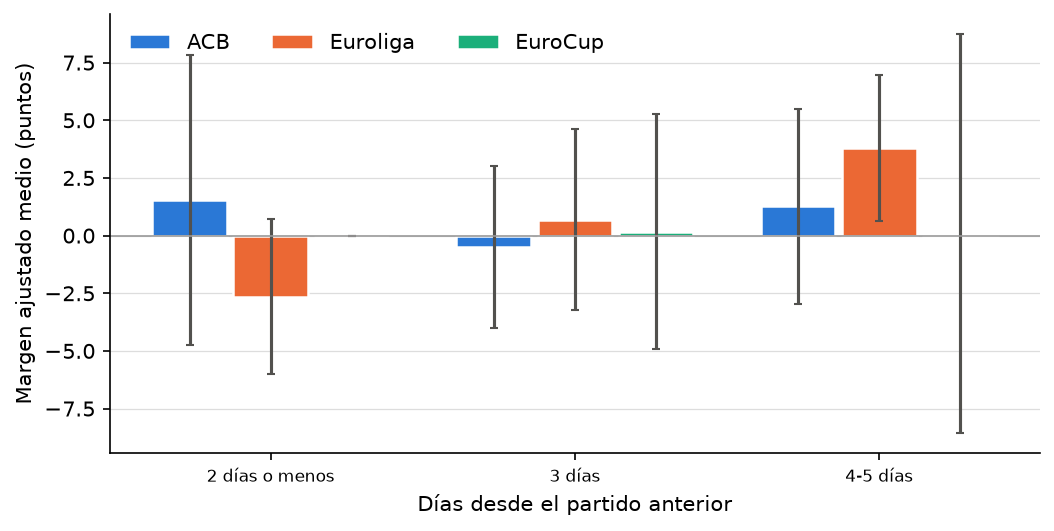

In [26]:
from controllers.mpl_charts import effect_png

display(ImagenPNG(effect_png(descanso, "Margen ajustado medio (puntos)", "Días desde el partido anterior")))

Cada barra es la media del margen ajustado en un tramo de descanso y la línea es el intervalo de ±1,96 errores estándar.
Si el intervalo contiene el cero, la diferencia puede deberse al azar. Son correlaciones, no causas.

## 7. Mapa

`map_data.py` prepara las tablas (partidos por sede, rutas y un cuadro por mes) y `map_charts.py` las convierte en
figuras de Plotly. `route_lines` dibuja las rutas más repetidas de cada competición. Con un único ranking, la ACB
quedaría sin líneas: cada viaje se hace una vez por temporada y las rutas europeas se repiten más.

In [27]:
#| archivo: controllers/map_data.py
"""Datos del mapa interactivo: sedes por competición, rutas de viaje, acumulado por meses y partidos de una sede."""
import pandas as pd

from controllers.charts import COMP_NAMES
from controllers.ingest import haversine_km
from controllers.views import add_crests

TOP_ROUTES = 15  # sin club elegido, el mapa dibuja solo las rutas más repetidas de cada competición para no taparse
MONTHS = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
          "noviembre", "diciembre"]
ROUTE_COLUMNS = ["competicion_id", "veces", "km", "origen_nombre", "origen_lat", "origen_lon",
                 "destino_nombre", "destino_lat", "destino_lon"]


def venue_stats(metrics: pd.DataFrame, venues: pd.DataFrame, names: dict[int, str]) -> pd.DataFrame:
    """Partidos por sede y competición, con coordenadas, total de la sede y clubes que juegan en casa allí."""
    games = metrics.drop_duplicates("partido_id")
    counts = games.groupby(["sede_id", "competicion_id"]).size().rename("partidos").reset_index()
    counts["total"] = counts.groupby("sede_id")["partidos"].transform("sum")
    clubs = (metrics[metrics["home"] == 1].groupby("sede_id")["club_id"]
             .apply(lambda ids: ", ".join(sorted({names[i] for i in ids}))).rename("clubes"))
    out = counts.merge(venues[["id", "nombre", "ciudad", "pais", "lat", "lon"]], left_on="sede_id", right_on="id")
    out = out.drop(columns="id").merge(clubs, left_on="sede_id", right_index=True, how="left")
    return out.fillna({"clubes": ""})


def route_lines(metrics: pd.DataFrame, venues: pd.DataFrame, top: int | None = None) -> pd.DataFrame:
    """Viajes como visitante de la sede base a la del partido, por competición, con número de veces y km (ida y vuelta).

    Con `top` quedan las `top` rutas más repetidas de cada competición y, a igualdad de veces, las más largas. Se
    eligen por competición porque en la ACB cada viaje se hace una vez por temporada: en un único ranking las rutas
    europeas, que se repiten entre temporadas y fases, la dejarían fuera del mapa.
    """
    away = metrics[metrics["home"] == 0].dropna(subset=["base_sede_id", "sede_id"])
    if away.empty:
        return pd.DataFrame(columns=ROUTE_COLUMNS)
    trips = away.groupby(["base_sede_id", "sede_id", "competicion_id"]).size().rename("veces").reset_index()
    coords = venues.set_index("id")[["nombre", "lat", "lon"]]
    origin = coords.add_prefix("origen_").loc[trips["base_sede_id"]].reset_index(drop=True)
    target = coords.add_prefix("destino_").loc[trips["sede_id"]].reset_index(drop=True)
    out = pd.concat([trips.reset_index(drop=True), origin, target], axis=1)
    out["km"] = [2 * haversine_km(r.origen_lat, r.origen_lon, r.destino_lat, r.destino_lon) for r in out.itertuples()]
    out = out[out["km"] > 0].sort_values(["veces", "km"], ascending=False)
    if top:
        out = out.groupby("competicion_id", sort=False).head(top)
    return out[ROUTE_COLUMNS].reset_index(drop=True)


def month_label(period: pd.Period) -> str:
    """Periodo mensual -> «octubre 2025»."""
    return f"{MONTHS[period.month - 1]} {period.year}"


def month_frames(metrics: pd.DataFrame, venues: pd.DataFrame, names: dict[int, str],
                 with_routes: bool) -> list[tuple[str, pd.DataFrame, pd.DataFrame]]:
    """Un cuadro por mes con lo acumulado hasta el final de ese mes: (etiqueta, sedes, rutas).

    Las rutas solo se calculan con un club elegido: con todos los clubes se taparían entre sí.
    """
    months = metrics["fecha"].dt.to_period("M")
    frames = []
    for month in sorted(months.unique()):
        upto = metrics[months <= month]
        routes = route_lines(upto, venues) if with_routes else pd.DataFrame(columns=ROUTE_COLUMNS)
        frames.append((month_label(month), venue_stats(upto, venues, names), routes))
    return frames


def venue_options(stats: pd.DataFrame) -> dict[int, str]:
    """Sedes con partidos en el mapa, de la que más a la que menos, como {id: «Sede (Ciudad)»} para elegir una."""
    ranked = stats.groupby(["sede_id", "nombre", "ciudad"], dropna=False)["partidos"].sum().reset_index()
    ranked = ranked.sort_values(["partidos", "nombre"], ascending=[False, True])
    return {int(r.sede_id): f"{r.nombre} ({r.ciudad}) · {r.partidos} partidos" for r in ranked.itertuples()}


def venue_games(metrics: pd.DataFrame, venue_id: int, names: dict[int, str],
                crests: dict[str, str] | None = None) -> pd.DataFrame:
    """Partidos jugados en una sede, uno por partido, con local, visitante y resultado."""
    here = metrics[metrics["sede_id"] == venue_id].sort_values("home", ascending=False).drop_duplicates("partido_id")
    is_home = here["home"] == 1  # con un club elegido, un partido fuera aparece desde su punto de vista: se da la vuelta
    local_id = here["club_id"].where(is_home, here["rival_id"])
    away_id = here["rival_id"].where(is_home, here["club_id"])
    pts_local = here["pts_for"].where(is_home, here["pts_against"]).astype(int)
    pts_away = here["pts_against"].where(is_home, here["pts_for"]).astype(int)
    out = pd.DataFrame({
        "Fecha": here["fecha"].dt.date,
        "Competición": here["competicion_id"].map(COMP_NAMES),
        "Club": local_id.map(names),
        "Rival": away_id.map(names),
        "Resultado": pts_local.astype(str) + "-" + pts_away.astype(str),
    }).sort_values("Fecha").reset_index(drop=True)
    out = add_crests(out, crests)
    return out.rename(columns={"Club": "Local", "Rival": "Visitante", "Escudo rival": "Escudo visitante"})

In [28]:
#| archivo: controllers/map_charts.py
"""Mapa interactivo con fondo de calles (Plotly Scattermap): sedes por competición, rutas y animación por meses."""
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from controllers.charts import COMP_NAMES, COMP_ORDER, PALETTES
from controllers.labels import country_name

STYLES = {False: "carto-positron", True: "carto-darkmatter"}  # teselas gratuitas de Carto, sin clave
HEIGHT = 540


def _marker_size(games: pd.Series) -> pd.Series:
    """Diámetro en píxeles: crece con la raíz del número de partidos y se acota."""
    return (8 + 3.2 * np.sqrt(games)).clip(upper=34)


def _view(lat: pd.Series, lon: pd.Series) -> tuple[dict, float]:
    """Centro y zoom que encuadran todos los puntos (aproximado para un mapa de unos 900 x 540 píxeles)."""
    if lat.empty:
        return {"lat": 45.0, "lon": 12.0}, 3.0
    center = {"lat": float((lat.max() + lat.min()) / 2), "lon": float((lon.max() + lon.min()) / 2)}
    lon_span = max(float(lon.max() - lon.min()), 1.0) * 1.3
    lat_span = max(float(lat.max() - lat.min()), 1.0) * 1.3
    zoom_lon = np.log2(640 / lon_span)
    zoom_lat = np.log2(340 * np.cos(np.radians(center["lat"])) / lat_span)
    return center, float(np.clip(min(zoom_lon, zoom_lat), 2.0, 9.0))


def _hover_text(stats: pd.DataFrame) -> pd.Series:
    """Texto emergente de cada sede: lugar, partidos de la competición, total y clubes locales."""
    comp = stats["competicion_id"].map(COMP_NAMES)
    place = "<b>" + stats["nombre"] + "</b><br>" + stats["ciudad"].fillna("") + ", " + stats["pais"].map(country_name)
    games = comp + ": " + stats["partidos"].astype(str) + " partidos"
    total = np.where(stats["total"] > stats["partidos"], "<br>Total en la sede: " + stats["total"].astype(str), "")
    clubs = np.where(stats["clubes"] != "", "<br>Clubes: " + stats["clubes"], "")
    return place + "<br>" + games + total + clubs


def _venue_trace(stats: pd.DataFrame, comp: str, pal: dict, show_legend: bool = True) -> go.Scattermap:
    part = stats[stats["competicion_id"] == comp]
    empty = part.empty  # un punto vacío mantiene la competición en la leyenda aunque aún no tenga partidos
    return go.Scattermap(
        lat=[None] if empty else part["lat"], lon=[None] if empty else part["lon"], mode="markers",
        name=COMP_NAMES[comp], legendgroup=comp,
        showlegend=show_legend, marker={"size": 10 if empty else _marker_size(part["partidos"]), "color": pal[comp], "opacity": 0.8},
        customdata=part[["sede_id"]].to_numpy(), text=_hover_text(part) if len(part) else [],
        hovertemplate="%{text}<extra></extra>",
    )


def _route_traces(routes: pd.DataFrame, pal: dict) -> list[go.Scattermap]:
    """Una línea por ruta, más gruesa cuanto más veces se repite, y un punto en su mitad con los datos del viaje."""
    traces = []
    mid_lat, mid_lon, mid_text, mid_color = [], [], [], []
    for r in routes.itertuples():
        traces.append(go.Scattermap(
            lat=[r.origen_lat, r.destino_lat], lon=[r.origen_lon, r.destino_lon], mode="lines", hoverinfo="skip",
            line={"width": 1.5 + min(r.veces, 8) * 0.7, "color": pal[r.competicion_id]}, opacity=0.55,
            showlegend=False,
        ))
        mid_lat.append((r.origen_lat + r.destino_lat) / 2)
        mid_lon.append((r.origen_lon + r.destino_lon) / 2)
        mid_color.append(pal[r.competicion_id])
        mid_text.append(f"<b>{r.origen_nombre} → {r.destino_nombre}</b><br>{COMP_NAMES[r.competicion_id]}: "
                        f"{r.veces} viajes<br>{r.km:,.0f} km ida y vuelta".replace(",", "."))
    if mid_lat:
        traces.append(go.Scattermap(
            lat=mid_lat, lon=mid_lon, mode="markers", marker={"size": 7, "color": mid_color, "opacity": 0.9},
            text=mid_text, hovertemplate="%{text}<extra></extra>", showlegend=False,
        ))
    return traces


def _base_layout(fig: go.Figure, dark: bool, lat: pd.Series, lon: pd.Series) -> go.Figure:
    pal = PALETTES[dark]
    center, zoom = _view(lat, lon)
    fig.update_layout(
        height=HEIGHT, paper_bgcolor="rgba(0,0,0,0)", font={"color": pal["ink"], "size": 13},
        margin={"l": 0, "r": 0, "t": 30, "b": 0},
        legend={"orientation": "h", "yanchor": "bottom", "y": 1.0, "xanchor": "left", "x": 0, "title": None,
                "bgcolor": "rgba(0,0,0,0)"},
        map={"style": STYLES[dark], "center": center, "zoom": zoom},
    )
    return fig


def _highlight_trace(stats: pd.DataFrame, venue_id: int, pal: dict) -> go.Scattermap:
    """Círculo grande y translúcido bajo la sede elegida."""
    part = stats[stats["sede_id"] == venue_id]
    size = float(_marker_size(part["total"]).max()) + 16 if len(part) else 0
    return go.Scattermap(lat=part["lat"].head(1), lon=part["lon"].head(1), mode="markers", hoverinfo="skip",
                         marker={"size": size, "color": pal["ink"], "opacity": 0.3}, showlegend=False)


def detail_map_figure(stats: pd.DataFrame, routes: pd.DataFrame, dark: bool, highlight: int | None = None) -> go.Figure:
    """Mapa con calles: sedes por competición (la leyenda las enciende y apaga), rutas de viaje y, si se elige, una sede resaltada."""
    pal = PALETTES[dark]
    fig = go.Figure()
    for trace in _route_traces(routes, pal):
        fig.add_trace(trace)
    if highlight is not None:
        fig.add_trace(_highlight_trace(stats, highlight, pal))
    for comp in COMP_ORDER:  # las sedes van encima de las rutas para poder pulsarlas
        if (stats["competicion_id"] == comp).any():
            fig.add_trace(_venue_trace(stats, comp, pal))
    return _base_layout(fig, dark, stats["lat"], stats["lon"])


def _frame_traces(stats: pd.DataFrame, routes: pd.DataFrame, pal: dict) -> list[go.Scattermap]:
    """Seis trazas fijas por cuadro: sedes de cada competición y rutas de cada competición."""
    traces = [_venue_trace(stats, comp, pal) for comp in COMP_ORDER]
    for comp in COMP_ORDER:
        part = routes[routes["competicion_id"] == comp]
        lat, lon = [], []
        for r in part.itertuples():
            lat += [r.origen_lat, r.destino_lat, None]
            lon += [r.origen_lon, r.destino_lon, None]
        traces.append(go.Scattermap(lat=lat, lon=lon, mode="lines", line={"width": 2.5, "color": pal[comp]},
                                    opacity=0.55, hoverinfo="skip", showlegend=False))
    return traces


def animated_map_figure(frames: list[tuple[str, pd.DataFrame, pd.DataFrame]], dark: bool) -> go.Figure:
    """Mapa animado: un cuadro por mes con las sedes y los viajes acumulados hasta entonces."""
    pal = PALETTES[dark]
    _, stats, routes = frames[0]
    fig = go.Figure(data=_frame_traces(stats, routes, pal))
    fig.frames = [go.Frame(name=name, data=_frame_traces(s, r, pal), traces=list(range(6))) for name, s, r in frames]
    everything = pd.concat([f[1] for f in frames]) if frames else pd.DataFrame({"lat": [], "lon": []})
    _base_layout(fig, dark, everything["lat"], everything["lon"])
    play = {"frame": {"duration": 1100, "redraw": True}, "transition": {"duration": 0}, "fromcurrent": True}
    fig.update_layout(
        margin={"l": 24, "r": 24, "t": 30, "b": 110},
        updatemenus=[{
            "type": "buttons", "direction": "left", "x": 0.0, "y": 0.0, "xanchor": "left", "yanchor": "top",
            "pad": {"t": 8, "l": 4}, "bgcolor": pal["surface"], "bordercolor": pal["grid"],
            "buttons": [
                {"label": "Reproducir", "method": "animate", "args": [None, play]},
                {"label": "Pausa", "method": "animate",
                 "args": [[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}]},
            ],
        }],
        sliders=[{
            "x": 0.0, "len": 1.0, "pad": {"t": 64, "b": 0, "l": 4, "r": 4}, "font": {"size": 11},
            "currentvalue": {"prefix": "Acumulado hasta: ", "font": {"size": 13}, "xanchor": "left"},
            "steps": [{"label": name[:3] + " " + name[-4:], "method": "animate",
                       "args": [[name], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]}
                      for name, _, _ in frames],
        }],
    )
    return fig

In [29]:
from controllers.map_data import TOP_ROUTES, route_lines, venue_stats
from controllers.views import filter_metrics

filtrado = filter_metrics(metricas, temporada, ["ACB", "E", "U"])
estadisticas = venue_stats(filtrado, venues, nombres)
rutas = route_lines(filtrado, venues, TOP_ROUTES)

print(f"Sedes con partidos: {estadisticas['sede_id'].nunique()}")
print(f"Rutas dibujadas (las {TOP_ROUTES} más repetidas de cada competición): {len(rutas)}")
display(rutas.groupby("competicion_id").size().rename("rutas").to_frame())

Sedes con partidos: 64
Rutas dibujadas (las 15 más repetidas de cada competición): 45


,rutas
competicion_id,
ACB,15
E,15
U,15


## 8. Impresión y PDF

Botón de imprimir: Streamlit no lo incluye. Se crea con HTML dentro de un `iframe` (`st.iframe`) que llama a
`window.parent.print()`. Antes de imprimir, el script reduce los gráficos de Plotly más anchos que la hoja, porque tienen
un ancho fijo en píxeles, y los restaura al terminar. `styles/print.css` oculta el menú y los botones, pone la hoja en
horizontal (`@page` va fuera de `@media`) y evita que un gráfico se parta entre páginas. `common/utils.py` carga la hoja
de estilo.

La tabla interactiva de Streamlit se dibuja en un lienzo (`canvas`) y al imprimir sale recortada por la derecha.
`print_table` añade una copia en HTML que solo se ve al imprimir, sin escudos ni banderas y limitada a las primeras
filas; la tabla interactiva y su hueco se ocultan en esa vista.

In [30]:
#| archivo: common/utils.py
"""Utilidades compartidas: carga de hojas de estilo de la carpeta styles/."""
from functools import cache
from pathlib import Path

import streamlit as st

STYLES_DIR = Path(__file__).resolve().parent.parent / "styles"


@cache
def load_css(name: str) -> str:
    """Contenido de un archivo de styles/ (por ejemplo, «print.css»)."""
    return (STYLES_DIR / name).read_text(encoding="utf-8")


def inject_css(name: str) -> None:
    """Aplica a la página una hoja de estilo de styles/."""
    st.markdown(f"<style>{load_css(name)}</style>", unsafe_allow_html=True)

In [31]:
#| archivo: common/print_tools.py
"""Botón de imprimir la página y estilos de impresión."""
import pandas as pd
import streamlit as st

from common.utils import inject_css

IMAGE_COLUMNS = ("Escudo", "Escudo rival", "Escudo visitante", "Bandera")

PRINT_BUTTON = """
<style>
html, body { margin: 0; padding: 0; background: transparent; }
button { box-sizing: border-box; width: 100%; height: 40px; padding: 0 12px; border-radius: 8px;
         border: 1px solid #ff4b4b; background: #ff4b4b; color: #ffffff; cursor: pointer;
         font: 400 14px "Source Sans", "Source Sans Pro", sans-serif; white-space: nowrap; }
button:hover { border-color: #ff6b6b; background: #ff6b6b; }
</style>
<button onclick="imprimir()">🖨️ Imprimir página</button>
<script>
// Los gráficos de Plotly tienen un ancho fijo en píxeles: se reducen para que quepan en la hoja y se restauran después.
function imprimir() {
  const padre = window.parent;
  const MAX = 680;  // ancho útil de un A4 vertical; Safari ignora @page y suele imprimir en vertical
  padre.document.querySelectorAll('[data-testid="stPlotlyChart"]').forEach((el) => {
    const ancho = el.getBoundingClientRect().width;
    if (ancho > MAX) { el.style.zoom = String(MAX / ancho); el.dataset.ajustado = "1"; }
  });
  padre.addEventListener("afterprint", () => {
    padre.document.querySelectorAll('[data-ajustado]').forEach((el) => { el.style.zoom = ""; delete el.dataset.ajustado; });
  }, { once: true });
  padre.print();
}
</script>
"""


def inject_print_css() -> None:
    """Estilos de impresión (styles/print.css): ocultan menú y botones. Se llama desde el menú para no añadir un hueco junto a los botones."""
    inject_css("print.css")


def print_button() -> None:
    """Botón que abre el diálogo de impresión del navegador."""
    st.iframe(PRINT_BUTTON, height=40)


def print_table(table: pd.DataFrame, rows: int = 40) -> None:
    """Copia estática de una tabla, visible solo al imprimir: la tabla interactiva se dibuja en un lienzo y sale recortada."""
    shown = table.drop(columns=[c for c in IMAGE_COLUMNS if c in table.columns]).head(rows)
    # Los números enteros guardados como decimales (4466.0) se muestran sin decimales.
    formats = {c: (lambda v: "" if pd.isna(v) else str(int(v)) if v == int(v) else str(round(v, 4)))
               for c in shown.select_dtypes("number").columns}
    note = f"<p>Se imprimen las {len(shown)} primeras filas de {len(table)}.</p>" if len(table) > rows else ""
    st.html(f'<div class="print-only">{shown.to_html(index=False, border=0, na_rep="", formatters=formats)}{note}</div>')

Exportar a PDF: `common/pdf_generator.py` crea el PDF en memoria con `fpdf2` y `controllers/reports.py` decide el
contenido de cada informe. El botón es un `st.download_button` con una función en `data=`. Streamlit la ejecuta al
pulsar, fuera del hilo del script, y allí `st.session_state` no existe. Por eso el usuario se guarda en una variable
antes de crear el botón.

In [32]:
#| archivo: common/pdf_generator.py
"""Informe PDF en memoria con fpdf2. Fuente DejaVu (viene con Matplotlib) para tildes, ñ, ≥ y ±."""
from dataclasses import dataclass
from datetime import datetime
from io import BytesIO
from pathlib import Path

import matplotlib
import pandas as pd
from fpdf import FPDF
from PIL import Image as PILImage

FONT_DIR = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
MAX_CELL_CHARS = 26


@dataclass
class Table:
    """Tabla del informe; solo se imprimen las primeras `max_rows` filas."""

    title: str
    df: pd.DataFrame
    max_rows: int = 30


@dataclass
class Image:
    """Gráfica PNG del informe."""

    title: str
    png: bytes
    note: str = ""


class _Report(FPDF):
    def footer(self) -> None:
        self.set_y(-12)
        self.set_font("DejaVu", "", 8)
        self.set_text_color(110)
        self.cell(0, 8, f"Página {self.page_no()}", align="C")


def _fmt(value: object) -> str:
    if value is None or value is pd.NA or (isinstance(value, float) and pd.isna(value)):
        return ""
    text = f"{value:g}" if isinstance(value, float) else str(value)
    return text if len(text) <= MAX_CELL_CHARS else text[: MAX_CELL_CHARS - 1] + "…"


def build_report(title: str, user: str, filters: dict[str, str], blocks: list[Table | Image]) -> bytes:
    """Genera el PDF (horizontal, A4) y devuelve sus bytes."""
    pdf = _Report(orientation="L", unit="mm", format="A4")
    pdf.add_font("DejaVu", "", str(FONT_DIR / "DejaVuSans.ttf"))
    pdf.add_font("DejaVu", "B", str(FONT_DIR / "DejaVuSans-Bold.ttf"))
    pdf.set_auto_page_break(auto=True, margin=15)
    pdf.add_page()
    pdf.set_font("DejaVu", "B", 16)
    pdf.cell(0, 10, title, new_x="LMARGIN", new_y="NEXT")
    pdf.set_font("DejaVu", "", 9)
    pdf.set_text_color(90)
    pdf.cell(0, 6, f"Generado el {datetime.now().astimezone():%d/%m/%Y} por {user}", new_x="LMARGIN", new_y="NEXT")
    if filters:
        pdf.multi_cell(0, 5, " · ".join(f"{k}: {v}" for k, v in filters.items()), new_x="LMARGIN", new_y="NEXT")
    pdf.set_text_color(0)
    pdf.ln(3)

    for block in blocks:
        if isinstance(block, Image) and pdf.will_page_break(8 + _image_height(pdf, block) + 10):
            pdf.add_page()  # título y gráfica siempre en la misma página
        pdf.set_font("DejaVu", "B", 11)
        pdf.cell(0, 8, block.title, new_x="LMARGIN", new_y="NEXT")
        if isinstance(block, Table):
            _add_table(pdf, block)
        else:
            _add_image(pdf, block)
        pdf.ln(3)
    return bytes(pdf.output())


def _add_table(pdf: FPDF, block: Table) -> None:
    pdf.set_font("DejaVu", "", 7)
    if block.df.empty:
        pdf.cell(0, 6, "Sin datos con estos filtros.", new_x="LMARGIN", new_y="NEXT")
        return
    shown = block.df.head(block.max_rows)
    with pdf.table(text_align="LEFT", line_height=4.5, padding=0.6) as table:
        header = table.row()
        for col in shown.columns:
            header.cell(str(col))
        for row in shown.itertuples(index=False):
            cells = table.row()
            for value in row:
                cells.cell(_fmt(value))
    if len(block.df) > len(shown):
        pdf.set_font("DejaVu", "", 8)
        pdf.cell(0, 6, f"Se muestran {len(shown)} de {len(block.df)} filas.", new_x="LMARGIN", new_y="NEXT")


def _image_width(pdf: FPDF) -> float:
    return min(150, pdf.epw)  # a 150 mm caben dos gráficas por página horizontal


def _image_height(pdf: FPDF, block: Image) -> float:
    """Alto en mm que ocupará la gráfica al escalarla al ancho de la página."""
    width_px, height_px = PILImage.open(BytesIO(block.png)).size
    return _image_width(pdf) * height_px / width_px


def _add_image(pdf: FPDF, block: Image) -> None:
    pdf.image(BytesIO(block.png), x=pdf.l_margin, w=_image_width(pdf))
    if block.note:
        pdf.set_font("DejaVu", "", 8)
        pdf.set_text_color(90)
        pdf.multi_cell(0, 4.5, block.note, new_x="LMARGIN", new_y="NEXT")
        pdf.set_text_color(0)

In [33]:
#| archivo: controllers/reports.py
"""Montaje de los informes PDF de cada página a partir de los datos ya filtrados."""
import pandas as pd

from common.pdf_generator import Image, Table, build_report
from controllers.chart_data import (
    RESULT_MEASURES,
    TRIP_UNITS,
    add_result_columns,
    away_trip_effect,
    binned_effect,
    home_away_effect,
    rest_trip_grid,
)
from controllers.mpl_charts import (
    effect_png,
    km_by_club_png,
    rest_trip_heatmap_png,
    venue_map_png,
)

CAVEAT = "Las gráficas muestran correlaciones, no causas. Se omiten los tramos con menos de 5 partidos."


def trip_report(user: str, filters: dict[str, str], trips: pd.DataFrame, km: pd.DataFrame | None,
                venues: pd.DataFrame, lines: pd.DataFrame | None) -> bytes:
    """Informe de la página Calendario y viajes."""
    blocks: list[Table | Image] = [Table("Partidos jugados y kilómetros", trips)]
    if km is not None and not km.empty:
        blocks.append(Image("Km de viaje acumulados por club", km_by_club_png(km), "Ida y vuelta entre la sede base y la del partido."))
    if not venues.empty:
        blocks.append(Image("Sedes de los partidos", venue_map_png(venues, lines)))
    return build_report("Calendario y viajes", user, filters, blocks)


def _effect_block(title: str, data: pd.DataFrame, y_title: str, x_title: str, note: str) -> list[Image]:
    """Un bloque de gráfica de efecto; vacío si no queda ningún tramo con suficientes partidos."""
    return [Image(title, effect_png(data, y_title, x_title), note)] if not data.empty else []


def result_blocks(scope: pd.DataFrame, measure: str, unit: str) -> list[Table | Image]:
    """Gráficas de resultados y viaje; `scope` debe llevar las columnas de `add_result_columns`."""
    label = RESULT_MEASURES[measure]
    scope = add_result_columns(scope)
    away = scope[scope["home"] == 0]
    blocks: list[Table | Image] = list(_effect_block(
        "Victorias en casa y fuera", home_away_effect(scope, "win_pct"), "Victorias (%)", "Condición del partido",
        "Media con ±1,96 errores estándar. " + CAVEAT,
    ))
    if not away.empty:
        blocks += _effect_block(
            f"{label} fuera de casa según el viaje", away_trip_effect(scope, unit, measure), label, TRIP_UNITS[unit],
            "Solo partidos fuera. Las horas son una estimación (autobús o avión con 3 h de aeropuerto). " + CAVEAT,
        )
        grid = rest_trip_grid(scope, measure)
        if grid["media"].notna().any():  # sin ninguna celda con 15 partidos el mapa saldría vacío
            blocks.append(Image(
                f"{label} fuera de casa según descanso y viaje",
                rest_trip_heatmap_png(grid, label, float(away[measure].mean())),
                f"Color respecto a la media de los partidos fuera ({round(away[measure].mean(), 1) + 0.0:.1f}). "
                "Celdas con menos de 15 partidos en blanco. " + CAVEAT,
            ))
    return blocks


def fatigue_report(user: str, filters: dict[str, str], table: pd.DataFrame, scope: pd.DataFrame,
                   rotation_key: str, rotation_label: str, measure: str = "win_pct", unit: str = "km_trip") -> bytes:
    """Informe de la página Fatiga y rotaciones; `scope` son las métricas de todas las temporadas filtradas."""
    blocks: list[Table | Image] = [Table("Descanso, carga y rotación por partido", table)]
    if not scope.empty:
        blocks += _effect_block(
            "Rendimiento según el descanso", binned_effect(scope, "rest_days", "margin_resid"),
            "Margen ajustado medio (puntos)", "Días desde el partido anterior",
            "Media por tramo con ±1,96 errores estándar. " + CAVEAT,
        )
        blocks += _effect_block(
            f"{rotation_label} según los km de los últimos 7 días", binned_effect(scope, "km_7d", rotation_key),
            rotation_label, "Km de viaje acumulados en 7 días", CAVEAT,
        )
        blocks.extend(result_blocks(scope, measure, unit))
    return build_report("Fatiga y rotaciones", user, filters, blocks)

In [34]:
from controllers.chart_data import km_by_club, venue_counts
from controllers.reports import trip_report
from controllers.views import seasons_label, trip_table

# Se monta el mismo informe que descarga el botón de la página 1, con los mismos filtros por defecto.
tabla_viajes = trip_table(filtrado, nombres, venues).drop(columns="País")
filtros = {"Temporada": seasons_label(temporada), "Competiciones": "ACB, Euroliga, EuroCup", "Club": "Todos"}
pdf = trip_report("demo", filtros, tabla_viajes, km_by_club(filtrado, nombres), venue_counts(filtrado, venues), None)

print(f"PDF generado en memoria: {len(pdf) / 1024:.0f} KB | empieza por {pdf[:5]!r} (la firma de un PDF válido)")

PDF generado en memoria: 166 KB | empieza por b'%PDF-' (la firma de un PDF válido)


## 9. Login y menú

`controllers/auth.py` valida las credenciales sin importar Streamlit. Compara con `hmac.compare_digest` y espera
`admin` / `admin` por defecto, como pide el enunciado; `APP_USER` y `APP_PASSWORD` lo sustituyen. `common/login.py`
muestra el formulario y guarda el usuario en `st.session_state`. `common/menu.py` crea el menú y reúne el acceso en
`iniciar_pagina`.

In [35]:
#| archivo: controllers/auth.py
"""Validación de credenciales. Usuario y clave salen del entorno; por defecto admin/admin (lo exige el enunciado)."""
import hmac
import os

DEFAULT_USER = "admin"
DEFAULT_PASSWORD = "admin"


def validate_credentials(user: str, password: str) -> bool:
    """Compara usuario y clave en tiempo constante; rechaza vacíos."""
    if not user or not password:
        return False
    expected_user = os.getenv("APP_USER", DEFAULT_USER)
    expected_password = os.getenv("APP_PASSWORD", DEFAULT_PASSWORD)
    user_ok = hmac.compare_digest(user.encode(), expected_user.encode())
    password_ok = hmac.compare_digest(password.encode(), expected_password.encode())
    return user_ok and password_ok

In [36]:
#| archivo: common/login.py
"""Login con estado de sesión de Streamlit."""
import streamlit as st

from controllers.auth import validate_credentials


def logout() -> None:
    """Borra la sesión y recarga la página."""
    st.session_state.clear()
    st.rerun()


def generar_login() -> bool:
    """Pinta el formulario si no hay sesión; devuelve True cuando hay usuario autenticado."""
    if "usuario" in st.session_state:
        return True
    st.title("Viajes y fatiga en baloncesto europeo")
    st.caption("Inicia sesión para ver la aplicación.")
    with st.form("login"):
        user = st.text_input("Usuario")
        password = st.text_input("Contraseña", type="password")
        submitted = st.form_submit_button("Entrar")
    if submitted:
        if validate_credentials(user, password):
            st.session_state["usuario"] = user
            st.rerun()
        st.error("Usuario o contraseña incorrectos.")
    return False

In [37]:
#| archivo: common/theme.py
"""Tema claro u oscuro del navegador, para elegir la paleta de los gráficos."""
import streamlit as st


def is_dark() -> bool:
    """True si Streamlit está en tema oscuro; claro si no se puede saber."""
    try:
        return st.context.theme.type == "dark"
    except (AttributeError, RuntimeError):
        return False

Streamlit vuelve a ejecutar el script entero en cada interacción. Lo que debe persistir entre ejecuciones se guarda en
`st.session_state` y los cálculos costosos, en la caché.

`iniciar_pagina` hace tres cosas: configura la página (`st.set_page_config`), exige sesión y muestra el menú. El menú
automático de Streamlit se desactiva en `.streamlit/config.toml` para controlar el orden y los iconos.

In [38]:
#| archivo: common/menu.py
"""Menú lateral común a todas las páginas."""
import streamlit as st

from common.login import generar_login, logout
from common.print_tools import inject_print_css


def number_formats(**formats: str) -> dict:
    """Configuración de columnas numéricas con formato fijo: {"Km": "%.0f"} -> NumberColumn(format="%.0f")."""
    return {name: st.column_config.NumberColumn(format=fmt) for name, fmt in formats.items()}


def image_columns() -> dict:
    """Columnas de escudo y bandera de las tablas: imagen pequeña y sin título."""
    return {name: st.column_config.ImageColumn(" ", width="small") for name in ("Escudo", "Escudo rival", "Escudo visitante", "Bandera")}


def crear_menu() -> None:
    """Enlaces a las páginas, usuario activo y botón de salir."""
    with st.sidebar:
        inject_print_css()
        st.title("Viajes y fatiga")
        st.page_link("home.py", label="Inicio", icon="🏠")
        st.page_link("pages/1_calendario_viajes.py", label="Calendario y viajes", icon="✈️")
        st.page_link("pages/2_fatiga_rotaciones.py", label="Fatiga y rotaciones", icon="🏀")
        st.divider()
        st.caption(f"Usuario: {st.session_state.get('usuario', '')}")
        if st.button("Salir"):
            logout()


def iniciar_pagina(titulo: str, icono: str) -> bool:
    """Configura la página, exige sesión y pinta el menú; devuelve False si hay que parar."""
    st.set_page_config(page_title=titulo, page_icon=icono, layout="wide")
    if not generar_login():
        return False
    crear_menu()
    return True

In [39]:
from controllers.auth import validate_credentials

for usuario, clave in [("admin", "admin"), ("admin", "otra"), ("", "admin"), ("admin", "")]:
    print(f"usuario={usuario!r:<8} clave={clave!r:<8} -> {validate_credentials(usuario, clave)}")

usuario='admin'  clave='admin'  -> True
usuario='admin'  clave='otra'   -> False
usuario=''       clave='admin'  -> False
usuario='admin'  clave=''       -> False


### Prueba con `AppTest`

`AppTest` ejecuta una página en memoria y permite pulsar sus widgets. La celda comprueba el acceso: sin sesión solo
aparece el formulario, una clave incorrecta se rechaza y una correcta guarda el usuario.

In [40]:
from streamlit.testing.v1 import AppTest

inicial = Path.cwd()
os.chdir(APP)  # las rutas de la app (data/, pages/) son relativas a la carpeta de home.py
try:
    at = AppTest.from_file(str(APP / "home.py"), default_timeout=60).run()
    print("1. Sin sesión:           campos de texto =", len(at.text_input), "| tablas =", len(at.dataframe))

    at.text_input[0].set_value("admin")
    at.text_input[1].set_value("incorrecta")
    at.button[0].click()
    at.run()
    print("2. Clave incorrecta:     mensajes de error =", [e.value for e in at.error])

    at.text_input[0].set_value("admin")
    at.text_input[1].set_value("admin")
    at.button[0].click()
    at.run()
    print("3. Clave correcta:       usuario en la sesión =", at.session_state["usuario"])
    print("   Contadores de la portada:", [(m.label, m.value) for m in at.metric])
finally:
    os.chdir(inicial)

1. Sin sesión:           campos de texto = 2 | tablas = 0
2. Clave incorrecta:     mensajes de error = ['Usuario o contraseña incorrectos.']
3. Clave correcta:       usuario en la sesión = admin
   Contadores de la portada: [('Partidos jugados', '2.521'), ('Clubes', '74'), ('Doble competición', '7')]


## 10. Páginas

Son la única capa que usa Streamlit de forma directa. Están en celdas Raw, porque solo se ejecutan con
`streamlit run`. Todo el contenido depende de `if iniciar_pagina(...)`: si no hay sesión, no se muestra nada. Cada página
repite la comprobación porque se puede abrir por su dirección sin pasar por la portada.

### `home.py`

Contadores, texto de ayuda y advertencia de que los resultados son correlaciones.

### `pages/1_calendario_viajes.py`

Orden de la página: imports, filtros, dos fuentes en tablas, gráficas y botones. `format_func` muestra «2026/27» y
devuelve `2026`. `key=` da a cada widget un nombre estable en `st.session_state`, y las dos páginas usan claves
distintas para no compartir filtros. `st.container()` reserva arriba el espacio de los botones, que se rellenan al final
con los filtros ya elegidos. Si un filtro no deja partidos, se muestra un aviso y se desactiva el botón de PDF.

### `pages/2_fatiga_rotaciones.py`

Sigue el mismo esquema con dos diferencias. La segunda fuente es una API que puede fallar: la llamada va en un `try` que
captura errores de red y de formato y muestra `st.error` sin detener la página. Las gráficas van seguidas, no en
pestañas, para que «Imprimir página» las incluya todas.

## 11. Pruebas

Las pruebas están en `tests/`, no se generan desde el cuaderno y se ejecutan sobre los `.py` exportados.

| Qué se prueba | Archivo |
|---|---|
| Controladores y modelos | `test_metrics.py`, `test_chart_data.py` |
| Base de datos | `test_db_integrity.py` |
| Lectura de la ACB | `test_acb_parse.py` |
| Interfaz y login (`AppTest`) | `test_app_flow.py` |

La celda siguiente ejecuta las de métricas y las de la ACB.

In [41]:
import importlib.util
import subprocess

if importlib.util.find_spec("pytest") is None:
    print("pytest no está instalado en este entorno: se omite esta celda (pip install pytest).")
else:
    resultado = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider",
                                "tests/test_metrics.py", "tests/test_acb_parse.py"],
                               cwd=APP, capture_output=True, text=True, check=False)
    print("\n".join(resultado.stdout.strip().splitlines()[-4:]))

............................                                             [100%]
28 passed in 0.38s


## 12. Exportación

`exportar` escribe los archivos marcados del cuaderno guardado. La celda comprueba que cada archivo es idéntico al de la
aplicación y que cada `.py` tiene sintaxis válida. Escribe en una carpeta temporal, así que no modifica nada.

In [42]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    archivos = exportar(Path(tmp))
    distintos, invalidos = [], []
    for ruta, contenido in archivos.items():
        real = APP / ruta
        if not real.exists() or real.read_text(encoding="utf-8") != contenido:
            distintos.append(ruta)
        if ruta.endswith(".py"):
            try:
                compile(contenido, ruta, "exec")
            except SyntaxError:
                invalidos.append(ruta)

por_tipo = pd.Series([Path(r).suffix for r in archivos]).value_counts()
print(f"Archivos generados desde el cuaderno: {len(archivos)} ({', '.join(f'{n} {t}' for t, n in por_tipo.items())})")
print(f"Líneas de código generadas: {sum(c.count(chr(10)) for c in archivos.values())}")
print(f"Idénticos a los de la aplicación: {len(archivos) - len(distintos)} de {len(archivos)} | diferentes: {distintos or 'ninguno'}")
print(f"Con sintaxis no válida: {invalidos or 'ninguno'}")

Archivos generados desde el cuaderno: 32 (29 .py, 1 .sql, 1 .css, 1 .toml)
Líneas de código generadas: 2339
Idénticos a los de la aplicación: 32 de 32 | diferentes: ninguno
Con sintaxis no válida: ninguno


Para regenerar la aplicación, con el cuaderno guardado:

```python
exportar(APP)
```

Después se prueba con `streamlit run home.py` y `pytest`.

### Actualizar los datos

```bash
python scripts/fetch_euroleague.py --force --from 2026 --to 2026   # Euroliga y EuroCup
python scripts/fetch_acb.py                                        # ACB
python scripts/build_db.py                                         # reconstruye la base
python scripts/precompute_metrics.py                               # regenera data/metricas.parquet
pytest
```

### Publicar

Se sube la carpeta a GitHub (el `.gitignore` excluye `.env` y `secrets.toml`) y se crea la aplicación en Streamlit
Community Cloud con `home.py` y Python 3.12. Tras cada cambio de datos hay que reiniciarla, porque la caché conserva los
anteriores.

## 13. Funciones de Streamlit

| Función | Uso |
|---|---|
| `st.set_page_config` | Título, icono y ancho de la página |
| `st.session_state` | Usuario y filtros |
| `st.form`, `st.text_input` | Formulario de acceso |
| `st.rerun` | Recargar tras entrar o salir |
| `st.page_link` | Menú lateral |
| `st.columns`, `st.container`, `st.expander` | Maquetación |
| `st.selectbox`, `st.multiselect`, `st.radio`, `st.checkbox` | Filtros |
| `st.dataframe`, `st.column_config` | Tablas |
| `st.plotly_chart` | Gráficas |
| `st.info`, `st.error` | Avisos |
| `st.download_button`, `st.iframe` | PDF e impresión |
| `st.cache_data`, `st.cache_resource` | Caché |